<a href="https://www.kaggle.com/code/zeryyern/grad-cam?scriptVersionId=371547727" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [ ]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

In [56]:
import os
import socket
from pathlib import Path

print("GPU available:", __import__("torch").cuda.is_available()
      if "torch" in globals() else "Checking after imports")

print("\nDatasets attached to Kaggle:")

for item in os.listdir("/kaggle/input"):
    print("-", item)

print("\nInternet connectivity:")

try:
    socket.create_connection(("download.pytorch.org", 443), timeout=5).close()
    print("Internet is available.")
except OSError:
    print("Internet is unavailable.")

print("\nKaggle working directory:")
print(os.listdir("/kaggle/working"))

GPU available: True

Datasets attached to Kaggle:
- datasets

Internet connectivity:
Internet is available.

Kaggle working directory:
['.virtual_documents', 'resnet50_standard_best.pth', 'convnext_tiny_standard_best.pth', 'baseline_checkpoints_backup.zip', 'DR_Explanation_Stability', 'state.db']


In [58]:
#Imports and files
import os
import sys 
import math
import random
import json
import time
import copy 
import glob
import shutil 
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
from torchvision.models import (
    resnet50,
    ResNet50_Weights,
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)

from scipy import stats
from skimage.metrics import structural_similarity

from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

USE_AMP = DEVICE == "cuda"

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not enabled.")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
OpenCV: 4.14.0
Device: cuda
GPU: Tesla T4


In [59]:
DEBUG = True

IMAGE_SIZE = 384
BATCH_SIZE = 8
EPOCHS = 12
PATIENCE = 4
LEARNING_RATE = 1e-4

SEEDS = [42, 123, 2026]

LAMBDAS = [0.1, 0.5, 1.0, 2.0]

NUM_WORKERS = min(4, os.cpu_count() or 2)

# Quality labels: verify these using the distribution in Cell 4.
QUALITY_GOOD = 0
QUALITY_USABLE = 1
QUALITY_REJECT = 2

# Synthetic degradation levels: mild, moderate, severe.
DEGRADATION_LEVELS = {
    "blur": [1.0, 2.0, 3.0],
    "noise": [0.02, 0.05, 0.10],
    "illumination": [0.20, 0.40, 0.60],
    "contrast": [0.70, 0.50, 0.30]
}

DEGRADATION_TYPES = list(DEGRADATION_LEVELS.keys())

INPUT_DIR = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working")

ROOT = WORK_DIR / "DR_Explanation_Stability"

CHECKPOINT_DIR = ROOT / "checkpoints"
CACHE_DIR = WORK_DIR / "DR_image_cache"

ROOT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

if DEBUG:
    EPOCHS = 1
    PATIENCE = 1
    SEEDS = [42]
    LAMBDAS = [0.5]
    BATCH_SIZE = 4

    MAX_TRAIN = 200
    MAX_VAL = 60
    MAX_TEST = 60
else:
    MAX_TRAIN = None
    MAX_VAL = None
    MAX_TEST = None

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

print("Configuration initialized.")
print("Debug mode:", DEBUG)
print("Image size:", IMAGE_SIZE)
print("Training epochs:", EPOCHS)
print("Degradation types:", DEGRADATION_TYPES)
print("Output:", ROOT)

Configuration initialized.
Debug mode: True
Image size: 384
Training epochs: 1
Degradation types: ['blur', 'noise', 'illumination', 'contrast']
Output: /kaggle/working/DR_Explanation_Stability


In [60]:
#LOCATING EYEQ ANNOTATION
def find_csv(pattern):

    matches = list(INPUT_DIR.rglob(pattern))

    if not matches:
        return None

    return matches[0]


LABEL_TRAIN = find_csv("Label_EyeQ_train*.csv")
LABEL_TEST = find_csv("Label_EyeQ_test*.csv")

print("EyeQ training CSV:", LABEL_TRAIN)
print("EyeQ testing CSV:", LABEL_TEST)

if LABEL_TRAIN is None or LABEL_TEST is None:

    raise FileNotFoundError(
        "EyeQ annotation files were not found.\n"
        "Use Kaggle Add Input to attach the dataset containing "
        "Label_EyeQ_train.csv and Label_EyeQ_test.csv."
    )

EyeQ training CSV: /kaggle/input/datasets/zeryyern/eyeq-dataset/EyeQ-master/data/Label_EyeQ_train.csv
EyeQ testing CSV: /kaggle/input/datasets/zeryyern/eyeq-dataset/EyeQ-master/data/Label_EyeQ_test.csv


In [61]:
#LOCATING AND INSPECTING REAL LABELS 
train_labels = pd.read_csv(LABEL_TRAIN)
test_labels = pd.read_csv(LABEL_TEST)

# Remove unnecessary index columns.
train_labels = train_labels.loc[
    :, ~train_labels.columns.astype(str).str.startswith("Unnamed")
]

test_labels = test_labels.loc[
    :, ~test_labels.columns.astype(str).str.startswith("Unnamed")
]

print("Training columns:", train_labels.columns.tolist())
print("Testing columns:", test_labels.columns.tolist())

required_columns = {"image", "quality", "DR_grade"}

assert required_columns.issubset(train_labels.columns), (
    f"Training CSV must contain {required_columns}"
)

assert required_columns.issubset(test_labels.columns), (
    f"Testing CSV must contain {required_columns}"
)

# Convert labels to numeric values.
for df in [train_labels, test_labels]:

    df["quality"] = pd.to_numeric(
        df["quality"],
        errors="coerce"
    )

    df["DR_grade"] = pd.to_numeric(
        df["DR_grade"],
        errors="coerce"
    )

    df.dropna(
        subset=["image", "quality", "DR_grade"],
        inplace=True
    )

    df["quality"] = df["quality"].astype(int)
    df["DR_grade"] = df["DR_grade"].astype(int)

    df["image"] = df["image"].astype(str).str.strip()

# Validate the label ranges.
assert set(train_labels["DR_grade"].unique()).issubset(set(range(5)))
assert set(test_labels["DR_grade"].unique()).issubset(set(range(5)))

print("\nTraining quality distribution:")
display(train_labels["quality"].value_counts().sort_index())

print("\nTraining DR distribution:")
display(train_labels["DR_grade"].value_counts().sort_index())

print("\nQuality versus DR grade:")
display(
    pd.crosstab(
        train_labels["quality"],
        train_labels["DR_grade"]
    )
)

print("\nTesting quality distribution:")
display(test_labels["quality"].value_counts().sort_index())

Training columns: ['image', 'quality', 'DR_grade']
Testing columns: ['image', 'quality', 'DR_grade']

Training quality distribution:


quality
0    8347
1    1876
2    2320
Name: count, dtype: int64


Training DR distribution:


DR_grade
0    9239
1     911
2    1809
3     333
4     251
Name: count, dtype: int64


Quality versus DR grade:


DR_grade,0,1,2,3,4
quality,,,,,
0,6342,699,1100,167,39
1,1353,103,283,79,58
2,1544,109,426,87,154



Testing quality distribution:


quality
0    8471
1    4558
2    3220
Name: count, dtype: int64

In [62]:
import os
print(os.listdir("/kaggle/input"))


['datasets']


In [63]:
INPUT_DIR = "/kaggle/input"

for root, dirs, files in os.walk(INPUT_DIR):

    level = root.replace(INPUT_DIR, "").count(os.sep)

    if level > 4:
        dirs[:] = []
        continue

    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:8]:
        print(f"{indent}    {file}")

    if len(files) > 8:
        print(f"{indent}    ... and {len(files) - 8} more files")

input/
    datasets/
        zeryyern/
            eyeq-dataset/
                EyeQ-master/
                    README.md
        makrovh/
            diabetic-retinopathy-blindness-detection-c-data/
                sampleSubmission.csv
                trainLabels.csv
                sample/
                    10_left.jpeg
                    10_right.jpeg
                    13_left.jpeg
                    13_right.jpeg
                    15_left.jpeg
                    15_right.jpeg
                    16_left.jpeg
                    16_right.jpeg
                    ... and 2 more files
                test_images_768/
                train_images_768/


In [65]:
from pathlib import Path

# Actual EyePACS dataset location
EYEPACS_DIR = Path(
    "/kaggle/input/datasets/makrovh/diabetic-retinopathy-blindness-detection-c-data"
)

# Actual EyeQ repository location
EYEQ_DIR = Path(
    "/kaggle/input/datasets/zeryyern/eyeq-dataset"
)

# EyePACS image directories
TRAIN_IMAGE_DIR = (
    EYEPACS_DIR / "train_images_768" / "train"
)

TEST_IMAGE_DIR = (
    EYEPACS_DIR / "test_images_768" / "test"
)

print("EyePACS directory exists:", EYEPACS_DIR.exists())
print("Training images exist:", TRAIN_IMAGE_DIR.exists())
print("Testing images exist:", TEST_IMAGE_DIR.exists())
print("EyeQ directory exists:", EYEQ_DIR.exists())

if not EYEPACS_DIR.exists():
    raise FileNotFoundError("EyePACS dataset directory not found.")

if not TRAIN_IMAGE_DIR.exists():
    raise FileNotFoundError("EyePACS training image directory not found.")

if not TEST_IMAGE_DIR.exists():
    raise FileNotFoundError("EyePACS testing image directory not found.")

print("\nDataset paths successfully verified.")

EyePACS directory exists: True
Training images exist: True
Testing images exist: True
EyeQ directory exists: True

Dataset paths successfully verified.


In [66]:
print("Searching for EyeQ annotation files...\n")

for csv_file in EYEQ_DIR.rglob("*.csv"):
    print(csv_file)

Searching for EyeQ annotation files...

/kaggle/input/datasets/zeryyern/eyeq-dataset/EyeQ-master/data/Label_EyeQ_test.csv
/kaggle/input/datasets/zeryyern/eyeq-dataset/EyeQ-master/data/Label_EyeQ_train.csv
/kaggle/input/datasets/zeryyern/eyeq-dataset/EyeQ-master/MCF_Net/result/DenseNet121_v3_v1.csv


In [67]:
train_images = list(TRAIN_IMAGE_DIR.glob("*"))

test_images = list(TEST_IMAGE_DIR.glob("*"))

print("Training images:", len(train_images))
print("Testing images:", len(test_images))

print("\nTraining examples:")

for image in train_images[:5]:
    print(image.name)

print("\nTesting examples:")

for image in test_images[:5]:
    print(image.name)

Training images: 35126
Testing images: 53576

Training examples:
10003_left.jpeg
10003_right.jpeg
10007_left.jpeg
10007_right.jpeg
10009_left.jpeg

Testing examples:
10000_left.jpeg
10000_right.jpeg
10001_left.jpeg
10001_right.jpeg
10002_left.jpeg


In [68]:
from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

csv_files = list(INPUT_DIR.rglob("*.csv"))

print("CSV files found:\n")

for file in csv_files:
    print(file)

CSV files found:

/kaggle/input/datasets/makrovh/diabetic-retinopathy-blindness-detection-c-data/sampleSubmission.csv
/kaggle/input/datasets/makrovh/diabetic-retinopathy-blindness-detection-c-data/trainLabels.csv
/kaggle/input/datasets/zeryyern/eyeq-dataset/EyeQ-master/data/Label_EyeQ_test.csv
/kaggle/input/datasets/zeryyern/eyeq-dataset/EyeQ-master/data/Label_EyeQ_train.csv
/kaggle/input/datasets/zeryyern/eyeq-dataset/EyeQ-master/MCF_Net/result/DenseNet121_v3_v1.csv


In [69]:
# Locate the two EyeQ annotation files
train_csvs = [
    p for p in csv_files
    if p.name.startswith("Label_EyeQ_train")
]

test_csvs = [
    p for p in csv_files
    if p.name.startswith("Label_EyeQ_test")
]

if not train_csvs or not test_csvs:
    raise FileNotFoundError(
        "Could not find both EyeQ train and test annotation CSV files."
    )

LABEL_TRAIN = train_csvs[0]
LABEL_TEST = test_csvs[0]

print("Training labels:", LABEL_TRAIN)
print("Testing labels:", LABEL_TEST)

eyeq_train = pd.read_csv(LABEL_TRAIN)
eyeq_test = pd.read_csv(LABEL_TEST)

# Remove unnecessary index columns, if present
eyeq_train = eyeq_train.loc[
    :, ~eyeq_train.columns.astype(str).str.startswith("Unnamed:")
]

eyeq_test = eyeq_test.loc[
    :, ~eyeq_test.columns.astype(str).str.startswith("Unnamed:")
]

print("\nTraining shape:", eyeq_train.shape)
print("Testing shape:", eyeq_test.shape)

print("\nColumns:", eyeq_train.columns.tolist())

display(eyeq_train.head())
display(eyeq_test.head())

Training labels: /kaggle/input/datasets/zeryyern/eyeq-dataset/EyeQ-master/data/Label_EyeQ_train.csv
Testing labels: /kaggle/input/datasets/zeryyern/eyeq-dataset/EyeQ-master/data/Label_EyeQ_test.csv

Training shape: (12543, 3)
Testing shape: (16249, 3)

Columns: ['image', 'quality', 'DR_grade']


,image,quality,DR_grade
0,10009_left.jpeg,0,0
1,10009_right.jpeg,0,0
2,10014_left.jpeg,2,0
3,10014_right.jpeg,2,0
4,10015_left.jpeg,0,0


,image,quality,DR_grade
0,1_right.jpeg,1,0
1,10001_right.jpeg,0,2
2,10004_right.jpeg,0,0
3,10008_left.jpeg,0,0
4,10016_right.jpeg,0,2


In [70]:
#Verifying actual eyepacs image directions 
from pathlib import Path

EYEPACS_DIR = Path(
    "/kaggle/input/datasets/makrovh/diabetic-retinopathy-blindness-detection-c-data"
)

TRAIN_IMAGE_DIR = EYEPACS_DIR / "train_images_768" / "train"
TEST_IMAGE_DIR = EYEPACS_DIR / "test_images_768" / "test"

print("Training directory exists:", TRAIN_IMAGE_DIR.exists())
print("Testing directory exists:", TEST_IMAGE_DIR.exists())

if not TRAIN_IMAGE_DIR.exists():
    raise FileNotFoundError(f"Missing: {TRAIN_IMAGE_DIR}")

if not TEST_IMAGE_DIR.exists():
    raise FileNotFoundError(f"Missing: {TEST_IMAGE_DIR}")

print("\nTraining image count:", len(list(TRAIN_IMAGE_DIR.iterdir())))
print("Testing image count:", len(list(TEST_IMAGE_DIR.iterdir())))

Training directory exists: True
Testing directory exists: True

Training image count: 35126
Testing image count: 53576


In [71]:
#Matching EyeQ annotations to real EyePacs images 
import os

# Build a filename-to-path index
image_extensions = {".jpg", ".jpeg", ".png"}

image_lookup = {}

for folder in [TRAIN_IMAGE_DIR, TEST_IMAGE_DIR]:
    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in image_extensions:
            image_lookup[path.name] = str(path)

print("Total indexed images:", len(image_lookup))

# Combine EyeQ annotations while preserving their original split
eyeq_train = eyeq_train.copy()
eyeq_test = eyeq_test.copy()

eyeq_train["source_split"] = "train"
eyeq_test["source_split"] = "test"

eyeq_all = pd.concat(
    [eyeq_train, eyeq_test],
    ignore_index=True
)

# Match image filenames
eyeq_all["file_path"] = eyeq_all["image"].map(image_lookup)

matched_df = eyeq_all[
    eyeq_all["file_path"].notna()
].copy()

unmatched_df = eyeq_all[
    eyeq_all["file_path"].isna()
].copy()

print("\nEyeQ annotations:", len(eyeq_all))
print("Successfully matched:", len(matched_df))
print("Unmatched annotations:", len(unmatched_df))

print(
    "Matching rate:",
    round(len(matched_df) / max(len(eyeq_all), 1) * 100, 2),
    "%"
)

display(matched_df.head())

Total indexed images: 88702

EyeQ annotations: 28792
Successfully matched: 28792
Unmatched annotations: 0
Matching rate: 100.0 %


,image,quality,DR_grade,source_split,file_path
0,10009_left.jpeg,0,0,train,/kaggle/input/datasets/makrovh/diabetic-retino...
1,10009_right.jpeg,0,0,train,/kaggle/input/datasets/makrovh/diabetic-retino...
2,10014_left.jpeg,2,0,train,/kaggle/input/datasets/makrovh/diabetic-retino...
3,10014_right.jpeg,2,0,train,/kaggle/input/datasets/makrovh/diabetic-retino...
4,10015_left.jpeg,0,0,train,/kaggle/input/datasets/makrovh/diabetic-retino...


In [72]:
#Validating Annotations 
print("DR grade distribution:")
print(matched_df["DR_grade"].value_counts(dropna=False).sort_index())

print("\nImage quality distribution:")
print(matched_df["quality"].value_counts(dropna=False).sort_index())

print("\nMissing values:")
print(matched_df[["image", "quality", "DR_grade", "file_path"]].isna().sum())

print("\nDuplicate image filenames:")
print(matched_df["image"].duplicated().sum())

print("\nDR grade values:")
print(sorted(matched_df["DR_grade"].dropna().unique()))

print("\nQuality values:")
print(sorted(matched_df["quality"].dropna().unique()))

DR grade distribution:
DR_grade
0    20601
1     2309
2     4453
3      781
4      648
Name: count, dtype: int64

Image quality distribution:
quality
0    16818
1     6434
2     5540
Name: count, dtype: int64

Missing values:
image        0
quality      0
DR_grade     0
file_path    0
dtype: int64

Duplicate image filenames:
0

DR grade values:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Quality values:
[np.int64(0), np.int64(1), np.int64(2)]


In [73]:
#Inspecting original train/ test split before training the original EyeQ tst set separately
# Cell 10: Inspect EyeQ train/test split

print("Number of images in each split:")
print(eyeq_all["source_split"].value_counts())

print("\nDR grade distribution by split:")
display(
    pd.crosstab(
        eyeq_all["source_split"],
        eyeq_all["DR_grade"],
        margins=True
    )
)

print("\nImage quality distribution by split:")
display(
    pd.crosstab(
        eyeq_all["source_split"],
        eyeq_all["quality"],
        margins=True
    )
)

print("\nQuality labels by meaning:")
quality_names = {
    0: "Good",
    1: "Usable",
    2: "Reject"
}

eyeq_all["quality_name"] = eyeq_all["quality"].map(quality_names)

display(
    eyeq_all.groupby(
        ["source_split", "quality_name"]
    ).size().unstack(fill_value=0)
)

Number of images in each split:
source_split
test     16249
train    12543
Name: count, dtype: int64

DR grade distribution by split:


DR_grade,0,1,2,3,4,All
source_split,,,,,,
test,11362,1398,2644,448,397,16249
train,9239,911,1809,333,251,12543
All,20601,2309,4453,781,648,28792



Image quality distribution by split:


quality,0,1,2,All
source_split,,,,
test,8471,4558,3220,16249
train,8347,1876,2320,12543
All,16818,6434,5540,28792



Quality labels by meaning:


quality_name,Good,Reject,Usable
source_split,,,
test,8471,3220,4558
train,8347,2320,1876


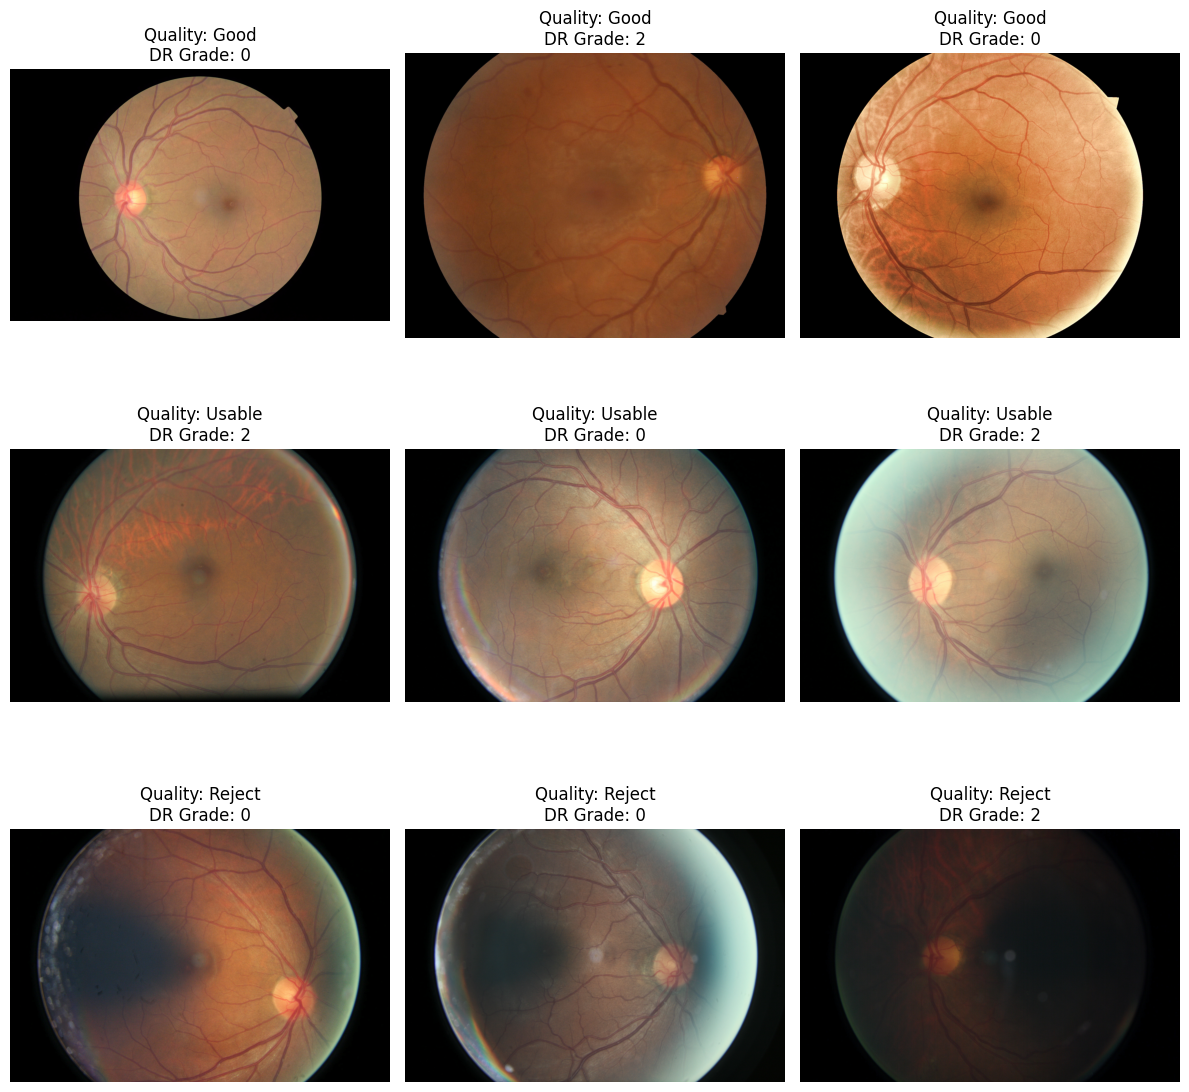

In [74]:
# Cell 11: Visual inspection of retinal images

import matplotlib.pyplot as plt
from PIL import Image
import random

random.seed(42)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for quality_value in [0, 1, 2]:
    samples = eyeq_all[
        (eyeq_all["quality"] == quality_value) &
        (eyeq_all["source_split"] == "train")
    ].sample(n=3, random_state=42)

    for j, (_, row) in enumerate(samples.iterrows()):
        image = Image.open(row["file_path"]).convert("RGB")

        ax = axes[quality_value, j]
        ax.imshow(image)
        ax.set_title(
            f"Quality: {quality_names[quality_value]}\n"
            f"DR Grade: {row['DR_grade']}"
        )
        ax.axis("off")

plt.tight_layout()
plt.show()

In [75]:
#Checking patient Overlap
# Cell 12: Check patient-level overlap

import re
from pathlib import Path

def extract_patient_id(filename):
    """
    Extract patient ID from EyePACS filename.
    Example: 10_left.jpeg -> 10
    """
    stem = Path(filename).stem
    return re.sub(r"_(left|right)$", "", stem, flags=re.IGNORECASE)


eyeq_all["patient_id"] = eyeq_all["image"].apply(
    extract_patient_id
)

train_patients = set(
    eyeq_all.loc[
        eyeq_all["source_split"] == "train",
        "patient_id"
    ]
)

test_patients = set(
    eyeq_all.loc[
        eyeq_all["source_split"] == "test",
        "patient_id"
    ]
)

overlap = train_patients.intersection(test_patients)

print("Unique training patients:", len(train_patients))
print("Unique testing patients:", len(test_patients))
print("Overlapping patients:", len(overlap))

if overlap:
    print("\nExamples of overlapping patient IDs:")
    print(list(overlap)[:20])
else:
    print("\nNo patient overlap detected.")

Unique training patients: 8614
Unique testing patients: 12048
Overlapping patients: 0

No patient overlap detected.


Creating Training andd Validating Sets 

In [76]:
#creating leakage free and validation split 
# Cell 13: Patient-level stratified train/validation split

from sklearn.model_selection import StratifiedGroupKFold

# Preserve the original EyeQ training and testing partitions
train_pool = eyeq_all[
    eyeq_all["source_split"] == "train"
].copy()

test_df = eyeq_all[
    eyeq_all["source_split"] == "test"
].copy()

# Split training data into 5 folds.
# One fold (~20%) will be used for validation.
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        X=train_pool,
        y=train_pool["DR_grade"],
        groups=train_pool["patient_id"]
    )
)

train_df = train_pool.iloc[train_idx].copy()
val_df = train_pool.iloc[val_idx].copy()

# Reset indices
train_df.reset_index(drop=True, inplace=True)
val_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)

print("Dataset sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

# Verify patient separation
train_ids = set(train_df["patient_id"])
val_ids = set(val_df["patient_id"])
test_ids = set(test_df["patient_id"])

print("\nPatient overlap:")
print("Train vs Validation:", len(train_ids & val_ids))
print("Train vs Test:", len(train_ids & test_ids))
print("Validation vs Test:", len(val_ids & test_ids))

# DR-grade distributions
print("\nDR-grade distribution:")
display(
    pd.DataFrame({
        "Train": train_df["DR_grade"].value_counts(normalize=True),
        "Validation": val_df["DR_grade"].value_counts(normalize=True),
        "Test": test_df["DR_grade"].value_counts(normalize=True)
    }).fillna(0).sort_index().round(3)
)

# Quality distributions
print("\nImage-quality distribution:")
display(
    pd.DataFrame({
        "Train": train_df["quality"].value_counts(normalize=True),
        "Validation": val_df["quality"].value_counts(normalize=True),
        "Test": test_df["quality"].value_counts(normalize=True)
    }).fillna(0).sort_index().round(3)
)

Dataset sizes:
Training: 10010
Validation: 2533
Testing: 16249

Patient overlap:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

DR-grade distribution:


,Train,Validation,Test
DR_grade,,,
0,0.738,0.729,0.699
1,0.071,0.078,0.086
2,0.144,0.146,0.163
3,0.026,0.028,0.028
4,0.020,0.018,0.024



Image-quality distribution:


,Train,Validation,Test
quality,,,
0,0.664,0.670,0.521
1,0.149,0.152,0.281
2,0.187,0.178,0.198


In [77]:
# building image dataset data loaders thereby targeting DR_Grade not quality
# Cell 14: Image preprocessing

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# ImageNet normalization for pretrained architectures
IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing configured.")
print("Image size:", IMAGE_SIZE)

Image preprocessing configured.
Image size: 224


In [78]:
# building image dataset data loaders thereby targeting DR_Grade not quality
# Cell 14: Image preprocessing

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# ImageNet normalization for pretrained architectures
IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing configured.")
print("Image size:", IMAGE_SIZE)

Image preprocessing configured.
Image size: 224


In [79]:
# Cell 16 (Updated): DataLoaders without multiprocessing

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Updated DataLoaders created successfully.")

Updated DataLoaders created successfully.


In [80]:
# Cell 17 (Updated): Inspect a sample batch

print("Loading training batch...")

batch = next(iter(train_loader))

images = batch["image"]
labels = batch["label"]
qualities = batch["quality"]

print("\nBatch loaded successfully!")
print("Image tensor shape:", images.shape)
print("DR labels shape:", labels.shape)
print("Quality labels shape:", qualities.shape)

print("\nDR grades:", labels.tolist())
print("Quality labels:", qualities.tolist())

print("\nGPU available:", torch.cuda.is_available())

Loading training batch...

Batch loaded successfully!
Image tensor shape: torch.Size([16, 3, 224, 224])
DR labels shape: torch.Size([16])
Quality labels shape: torch.Size([16])

DR grades: [0, 1, 2, 0, 0, 0, 0, 0, 0, 2, 0, 3, 0, 2, 0, 0]
Quality labels: [2, 0, 2, 0, 1, 0, 0, 2, 0, 0, 0, 2, 0, 0, 2, 0]

GPU available: True


In [81]:
# Cell 18: Inspect GPU and pretrained weight availability

import torch
import torchvision
import os

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("\nGPU information:")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("No GPU detected.")

# Check torchvision pretrained weight cache
checkpoint_dir = os.path.join(
    torch.hub.get_dir(),
    "checkpoints"
)

print("\nCheckpoint directory:", checkpoint_dir)

if os.path.exists(checkpoint_dir):
    checkpoint_files = os.listdir(checkpoint_dir)

    print("Available checkpoint files:")
    for file in checkpoint_files:
        print("-", file)
else:
    print("Checkpoint directory does not exist yet.")

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130

GPU information:
GPU: Tesla T4
GPU memory: 14.56 GB

Checkpoint directory: /root/.cache/torch/hub/checkpoints
Checkpoint directory does not exist yet.


#Testing connection 
# Cell 19: Test internet connectivity

import urllib.request

url = "https://download.pytorch.org"

try:
    response = urllib.request.urlopen(url, timeout=15)
    print("Internet connection successful!")
    print("HTTP status:", response.status)

except Exception as e:
    print("Internet connection failed:")
    print(e)

In [82]:
# Cell 20: Load ImageNet-pretrained architectures

import torch
import torch.nn as nn

from torchvision.models import (
    resnet50,
    ResNet50_Weights,
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

NUM_CLASSES = 5

print("Loading ResNet50 pretrained weights...")

resnet_weights = ResNet50_Weights.DEFAULT
resnet_model = resnet50(weights=resnet_weights)

resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    NUM_CLASSES
)

print("ResNet50 initialized successfully!")

print("\nLoading ConvNeXt Tiny pretrained weights...")

convnext_weights = ConvNeXt_Tiny_Weights.DEFAULT
convnext_model = convnext_tiny(weights=convnext_weights)

convnext_model.classifier[2] = nn.Linear(
    convnext_model.classifier[2].in_features,
    NUM_CLASSES
)

print("ConvNeXt Tiny initialized successfully!")

Loading ResNet50 pretrained weights...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 220MB/s]


ResNet50 initialized successfully!

Loading ConvNeXt Tiny pretrained weights...
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 205MB/s] 

ConvNeXt Tiny initialized successfully!


In [84]:
#Model Verification 
# Cell 21: Verify model outputs

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

resnet_model = resnet_model.to(device)
convnext_model = convnext_model.to(device)

sample_images = images[:2].to(device)

resnet_model.eval()
convnext_model.eval()

with torch.no_grad():
    resnet_output = resnet_model(sample_images)
    convnext_output = convnext_model(sample_images)

print("Device:", device)
print("ResNet50 output:", resnet_output.shape)
print("ConvNeXt output:", convnext_output.shape)

Device: cuda
ResNet50 output: torch.Size([2, 5])
ConvNeXt output: torch.Size([2, 5])


****Training ****

In [85]:
# Cell 22: Training configuration

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score, classification_report
from tqdm.auto import tqdm
import os
import copy

device = torch.device("cuda")

# Train one model at a time to conserve GPU memory
convnext_model = convnext_model.cpu()
resnet_model = resnet_model.to(device)

EPOCHS = 5          # Initial baseline run
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

NUM_CLASSES = 5

# Calculate class weights from training data only
class_counts = (
    train_df["DR_grade"]
    .value_counts()
    .reindex(range(NUM_CLASSES), fill_value=0)
    .sort_index()
)

class_weights = len(train_df) / (
    NUM_CLASSES * class_counts.values
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = AdamW(
    resnet_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scaler = torch.amp.GradScaler("cuda")

print("Training configuration ready.")
print("Class counts:", class_counts.to_dict())
print("Class weights:", class_weights.cpu().numpy())
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

Training configuration ready.
Class counts: {0: 7392, 1: 713, 2: 1439, 3: 261, 4: 205}
Class weights: [0.27083334 2.8078542  1.3912439  7.670498   9.765854  ]
Epochs: 5
Learning rate: 0.0001


In [86]:
# Cell 23: Training and evaluation functions

def train_one_epoch(model, loader, optimizer, criterion, scaler):

    model.train()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    for batch in tqdm(loader, desc="Training", leave=False):

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, epoch_f1


@torch.no_grad()
def evaluate_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_labels = []
    all_qualities = []

    for batch in tqdm(loader, desc="Validation", leave=False):

        images = batch["image"].to(device)
        labels = batch["label"].to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_qualities.extend(batch["quality"].numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return {
        "loss": epoch_loss,
        "accuracy": epoch_accuracy,
        "macro_f1": epoch_f1,
        "predictions": np.array(all_predictions),
        "labels": np.array(all_labels),
        "qualities": np.array(all_qualities)
    }


print("Training and evaluation functions defined.")

Training and evaluation functions defined.


In [87]:
# Cell 24: Train standard ResNet50

BEST_F1 = -1.0
BEST_RESNET_STATE = None

history_resnet = []

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_acc, train_f1 = train_one_epoch(
        resnet_model,
        train_loader,
        optimizer,
        criterion,
        scaler
    )

    val_results = evaluate_model(
        resnet_model,
        val_loader,
        criterion
    )

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Train Macro F1: {train_f1:.4f}")

    print(f"Validation Loss: {val_results['loss']:.4f}")
    print(f"Validation Accuracy: {val_results['accuracy']:.4f}")
    print(f"Validation Macro F1: {val_results['macro_f1']:.4f}")

    history_resnet.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_results["loss"],
        "val_accuracy": val_results["accuracy"],
        "val_macro_f1": val_results["macro_f1"]
    })

    # Save the model with the best validation macro F1
    if val_results["macro_f1"] > BEST_F1:

        BEST_F1 = val_results["macro_f1"]

        # FIXED: Correct dictionary comprehension syntax with key: value mapping
        BEST_RESNET_STATE = copy.deepcopy({
            key: value.detach().cpu()
            for key, value in resnet_model.state_dict().items()
        })

        torch.save(
            BEST_RESNET_STATE,
            "/kaggle/working/resnet50_standard_best.pth"
        )

        print("Best ResNet50 checkpoint saved.")

print("\nResNet50 baseline training completed.")
print("Best validation Macro F1:", BEST_F1)



Epoch 1/5


Training:   0%|          | 0/626 [00:00<?, ?it/s]

Validation:   0%|          | 0/159 [00:00<?, ?it/s]

Train Loss: 1.3749
Train Accuracy: 0.4922
Train Macro F1: 0.2934
Validation Loss: 1.4510
Validation Accuracy: 0.2839
Validation Macro F1: 0.1988
Best ResNet50 checkpoint saved.

Epoch 2/5


Training:   0%|          | 0/626 [00:00<?, ?it/s]

Validation:   0%|          | 0/159 [00:00<?, ?it/s]

... (6 outputs left out)

Train Loss: 0.9228
Train Accuracy: 0.5932
Train Macro F1: 0.4918
Validation Loss: 1.1843
Validation Accuracy: 0.6755
Validation Macro F1: 0.4720
Best ResNet50 checkpoint saved.

Epoch 5/5


Training:   0%|          | 0/626 [00:00<?, ?it/s]

Validation:   0%|          | 0/159 [00:00<?, ?it/s]

Train Loss: 0.8247
Train Accuracy: 0.6290
Train Macro F1: 0.5577
Validation Loss: 1.1801
Validation Accuracy: 0.5294
Validation Macro F1: 0.4084

ResNet50 baseline training completed.
Best validation Macro F1: 0.4719591278032242


In [88]:
# Cell 25: Display ResNet50 training history

history_resnet_df = pd.DataFrame(history_resnet)

display(
    history_resnet_df.round(4)
)

print("\nBest validation Macro F1:", round(BEST_F1, 4))
print("Checkpoint saved at:")
print("/kaggle/working/resnet50_standard_best.pth")

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1
0,1,1.3749,0.4922,0.2934,1.4510,0.2839,0.1988
1,2,1.1679,0.5134,0.3694,1.1817,0.6822,0.4079
2,3,1.0415,0.5689,0.4431,1.1472,0.4635,0.3942
3,4,0.9228,0.5932,0.4918,1.1843,0.6755,0.4720
4,5,0.8247,0.6290,0.5577,1.1801,0.5294,0.4084



Best validation Macro F1: 0.472
Checkpoint saved at:
/kaggle/working/resnet50_standard_best.pth


In [89]:
# Cell 26: Load best ResNet50 checkpoint

checkpoint_path = "/kaggle/working/resnet50_standard_best.pth"

best_checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

resnet_model.load_state_dict(best_checkpoint)
resnet_model.to(device)
resnet_model.eval()

print("Best ResNet50 checkpoint loaded.")
print("Selected epoch: 4")
print("Best validation Macro F1:", BEST_F1)

Best ResNet50 checkpoint loaded.
Selected epoch: 4
Best validation Macro F1: 0.4719591278032242


Validation:   0%|          | 0/159 [00:00<?, ?it/s]

Classification Report:

                  precision    recall  f1-score   support

           No DR       0.85      0.77      0.81      1847
            Mild       0.14      0.16      0.15       198
        Moderate       0.39      0.52      0.45       370
          Severe       0.56      0.49      0.52        72
Proliferative DR       0.36      0.54      0.43        46

        accuracy                           0.68      2533
       macro avg       0.46      0.50      0.47      2533
    weighted avg       0.71      0.68      0.69      2533



,Predicted 0,Predicted 1,Predicted 2,Predicted 3,Predicted 4
Actual 0,1427,172,220,4,24
Actual 1,128,32,37,1,0
Actual 2,124,21,192,17,16
Actual 3,7,0,25,35,5
Actual 4,2,1,13,5,25


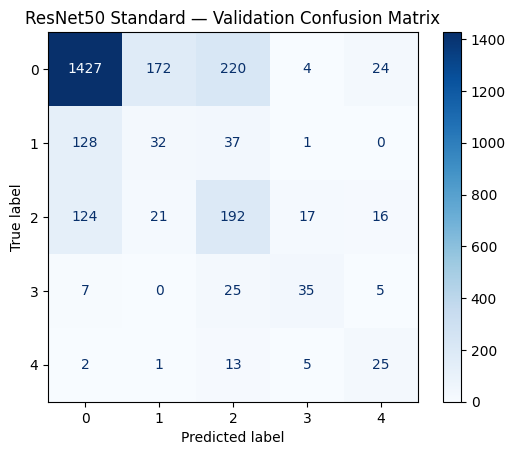

In [90]:
# Cell 27: Detailed validation evaluation

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

best_val_results = evaluate_model(
    resnet_model,
    val_loader,
    criterion
)

y_true = best_val_results["labels"]
y_pred = best_val_results["predictions"]

print("Classification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative DR"
        ],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

display(pd.DataFrame(
    cm,
    index=[f"Actual {i}" for i in range(5)],
    columns=[f"Predicted {i}" for i in range(5)]
))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ResNet50 Standard — Validation Confusion Matrix")
plt.show()

What this tells us
1. Grade 0 is recognised relatively well.

The model achieves an F1-score of 0.81 for No DR.

2. Grade 1 is our biggest classification weakness.

Its F1-score is only 0.15. The model frequently confuses Mild DR with other grades.

3. Grade 2 and Grade 3 show moderate performance.

Their F1-scores are 0.45 and 0.52, respectively.

4. Grade 4 needs further investigation.

In [91]:
# Cell 28: Quality-based validation performance

quality_labels = best_val_results["qualities"]

quality_names = {
    0: "Good",
    1: "Usable",
    2: "Reject"
}

quality_results = []

for quality_value, quality_name in quality_names.items():

    mask = quality_labels == quality_value

    if mask.sum() == 0:
        continue

    true_subset = y_true[mask]
    pred_subset = y_pred[mask]

    quality_results.append({
        "Quality": quality_name,
        "Images": int(mask.sum()),
        "Accuracy": accuracy_score(
            true_subset,
            pred_subset
        ),
        "Macro F1": f1_score(
            true_subset,
            pred_subset,
            average="macro",
            zero_division=0
        )
    })

quality_results_df = pd.DataFrame(quality_results)

display(quality_results_df.round(4))

,Quality,Images,Accuracy,Macro F1
0,Good,1697,0.7077,0.4836
1,Usable,385,0.6545,0.4494
2,Reject,451,0.5721,0.3725


As Image quality decreases, both accuracy and MAcro F1 decreases
Good: Macro F1 = 0.4836
Usable: Macro F1 = 0.4494
Reject: Macro F1 = 0.3725

In [92]:
# Cell 29: Configure ConvNeXt Tiny

# Move ResNet50 out of GPU memory
resnet_model = resnet_model.cpu()

# Move ConvNeXt to GPU
convnext_model = convnext_model.to(device)

# Fresh optimizer for ConvNeXt
convnext_optimizer = AdamW(
    convnext_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Fresh gradient scaler
convnext_scaler = torch.amp.GradScaler("cuda")

print("ConvNeXt Tiny ready for standard training.")
print("Device:", device)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)

ConvNeXt Tiny ready for standard training.
Device: cuda
Epochs: 5
Learning rate: 0.0001
Batch size: 16


In [1]:
# Cell 30: Train standard ConvNeXt Tiny

BEST_CONVNEXT_F1 = -1.0
BEST_CONVNEXT_STATE = None

history_convnext = []

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss, train_acc, train_f1 = train_one_epoch(
        convnext_model,
        train_loader,
        convnext_optimizer,
        criterion,
        convnext_scaler
    )

    val_results = evaluate_model(
        convnext_model,
        val_loader,
        criterion
    )

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Train Macro F1: {train_f1:.4f}")

    print(f"Validation Loss: {val_results['loss']:.4f}")
    print(f"Validation Accuracy: {val_results['accuracy']:.4f}")
    print(f"Validation Macro F1: {val_results['macro_f1']:.4f}")

    history_convnext.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_results["loss"],
        "val_accuracy": val_results["accuracy"],
        "val_macro_f1": val_results["macro_f1"]
    })

    if val_results["macro_f1"] > BEST_CONVNEXT_F1:

        BEST_CONVNEXT_F1 = val_results["macro_f1"]

        BEST_CONVNEXT_STATE = {
            key: value.detach().cpu().clone()
            for key, value in convnext_model.state_dict().items()
        }

        torch.save(
            BEST_CONVNEXT_STATE,
            "/kaggle/working/convnext_tiny_standard_best.pth"
        )

        print("Best ConvNeXt checkpoint saved.")

print("\nConvNeXt Tiny baseline training completed.")
print("Best validation Macro F1:", BEST_CONVNEXT_F1)


Epoch 1/5


Training:   0%|          | 0/626 [00:00<?, ?it/s]

Validation:   0%|          | 0/159 [00:00<?, ?it/s]

Train Loss: 0.5305
Train Accuracy: 0.7173
Train Macro F1: 0.7027
Validation Loss: 1.5321
Validation Accuracy: 0.5476
Validation Macro F1: 0.4263
Best ConvNeXt checkpoint saved.

Epoch 2/5


Training:   0%|          | 0/626 [00:00<?, ?it/s]

Validation:   0%|          | 0/159 [00:00<?, ?it/s]

... (6 outputs left out)

Train Loss: 0.3255
Train Accuracy: 0.8374
Train Macro F1: 0.8129
Validation Loss: 1.6125
Validation Accuracy: 0.5788
Validation Macro F1: 0.4654

Epoch 5/5


Training:   0%|          | 0/626 [00:00<?, ?it/s]

Validation:   0%|          | 0/159 [00:00<?, ?it/s]

Train Loss: 0.2775
Train Accuracy: 0.8513
Train Macro F1: 0.8274
Validation Loss: 1.9937
Validation Accuracy: 0.7710
Validation Macro F1: 0.4941

ConvNeXt Tiny baseline training completed.
Best validation Macro F1: 0.4948252496401212


In [2]:
# Cell 31: Review ConvNeXt results

history_convnext_df = pd.DataFrame(history_convnext)

display(history_convnext_df.round(4))

print(
    "\nBest ConvNeXt validation Macro F1:",
    round(BEST_CONVNEXT_F1, 4)
)

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1
0,1,0.5305,0.7173,0.7027,1.5321,0.5476,0.4263
1,2,0.4349,0.7562,0.7420,1.7178,0.7004,0.4948
2,3,0.3680,0.8039,0.7855,1.7955,0.5697,0.4644
3,4,0.3255,0.8374,0.8129,1.6125,0.5788,0.4654
4,5,0.2775,0.8513,0.8274,1.9937,0.7710,0.4941



Best ConvNeXt validation Macro F1: 0.4948


In [3]:
# Cell 32: Load best ConvNeXt checkpoint

convnext_checkpoint_path = (
    "/kaggle/working/convnext_tiny_standard_best.pth"
)

best_convnext_checkpoint = torch.load(
    convnext_checkpoint_path,
    map_location=device,
    weights_only=True
)

# Move ResNet50 out of GPU memory
resnet_model = resnet_model.cpu()

# Restore ConvNeXt
convnext_model.load_state_dict(best_convnext_checkpoint)
convnext_model = convnext_model.to(device)
convnext_model.eval()

print("Best ConvNeXt checkpoint loaded.")
print("Selected epoch: 2")
print("Best validation Macro F1:", BEST_CONVNEXT_F1)

# Evaluate
best_convnext_results = evaluate_model(
    convnext_model,
    val_loader,
    criterion
)

convnext_y_true = best_convnext_results["labels"]
convnext_y_pred = best_convnext_results["predictions"]
convnext_qualities = best_convnext_results["qualities"]

print("\nClassification Report:\n")

print(
    classification_report(
        convnext_y_true,
        convnext_y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative DR"
        ],
        zero_division=0
    )
)

Best ConvNeXt checkpoint loaded.
Selected epoch: 2
Best validation Macro F1: 0.4948252496401212


Validation:   0%|          | 0/159 [00:00<?, ?it/s]


Classification Report:

                  precision    recall  f1-score   support

           No DR       0.84      0.81      0.83      1847
            Mild       0.12      0.20      0.15       198
        Moderate       0.54      0.52      0.53       370
          Severe       0.65      0.36      0.46        72
Proliferative DR       0.61      0.43      0.51        46

        accuracy                           0.70      2533
       macro avg       0.55      0.46      0.49      2533
    weighted avg       0.73      0.70      0.71      2533



,Predicted 0,Predicted 1,Predicted 2,Predicted 3,Predicted 4
Actual 0,1498,263,83,0,3
Actual 1,134,39,25,0,0
Actual 2,125,33,191,13,8
Actual 3,9,1,34,26,2
Actual 4,7,0,18,1,20


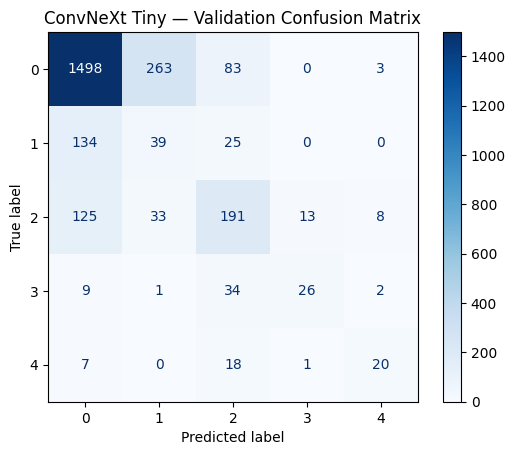

In [4]:
# Cell 33: ConvNeXt validation confusion matrix

convnext_cm = confusion_matrix(
    convnext_y_true,
    convnext_y_pred,
    labels=[0, 1, 2, 3, 4]
)

display(
    pd.DataFrame(
        convnext_cm,
        index=[f"Actual {i}" for i in range(5)],
        columns=[f"Predicted {i}" for i in range(5)]
    )
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=convnext_cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ConvNeXt Tiny — Validation Confusion Matrix")
plt.show()

In [5]:
# Cell 34: Quality-based ConvNeXt evaluation

quality_results = []

for quality_value, quality_name in quality_names.items():

    mask = convnext_qualities == quality_value

    if mask.sum() == 0:
        continue

    true_subset = convnext_y_true[mask]
    pred_subset = convnext_y_pred[mask]

    quality_results.append({
        "Quality": quality_name,
        "Images": int(mask.sum()),
        "Accuracy": accuracy_score(
            true_subset,
            pred_subset
        ),
        "Macro F1": f1_score(
            true_subset,
            pred_subset,
            average="macro",
            zero_division=0
        )
    })

convnext_quality_df = pd.DataFrame(quality_results)

display(convnext_quality_df.round(4))

,Quality,Images,Accuracy,Macro F1
0,Good,1697,0.7065,0.4654
1,Usable,385,0.6935,0.5121
2,Reject,451,0.6829,0.4549


From both experiments on RestNet50 and ConvNext we determine the ffl
1. ResNet50 performs better on Good images.
2. ConvNeXt performs better on Usable images.
3. ConvNeXt also performs slightly better on Reject images.
Both models experience declining performance on Reject images compared with Good images, although the difference is not identical.

Implementing Explanation Stability Aware Trainng 
Architecture         Training Strategy
RestNet50            Standard
RestNet50            Stability - Aware
ConvNext             Standard
ConVNext             Stability - Aware


In stability - We need to introduce two different pair of images 
1. Original Image
2. Degraded Image

Objectives
1. Classification: predict the correct DR grade
2. Explanation Stability: Encourage consistent GRAD - CAM explanations between original and degraded image 

In [6]:

from pathlib import Path
import torch
import shutil
import hashlib
import json
import zipfile

# Original checkpoint locations
work_dir = Path("/kaggle/working")

checkpoint_files = {
    "ResNet50": work_dir / "resnet50_standard_best.pth",
    "ConvNeXt Tiny": work_dir / "convnext_tiny_standard_best.pth"
}

# Backup directory
backup_dir = work_dir / "DR_Explanation_Stability" / "checkpoints" / "baseline_backup"
backup_dir.mkdir(parents=True, exist_ok=True)

backup_results = {}

for model_name, source in checkpoint_files.items():

    filename = source.name
    destination = backup_dir / filename

    if source.exists():
        shutil.copy2(source, destination)

    else:
        # Recover from the saved best model state if needed
        state_name = (
            "BEST_RESNET_STATE"
            if model_name == "ResNet50"
            else "BEST_CONVNEXT_STATE"
        )

        state = globals().get(state_name)

        if state is None:
            raise FileNotFoundError(
                f"{filename} and its in-memory best state are unavailable."
            )

        torch.save(state, destination)

    # Verify the backup
    loaded = torch.load(
        destination,
        map_location="cpu",
        weights_only=True
    )

    assert isinstance(loaded, dict) and len(loaded) > 0

    sha256 = hashlib.sha256(destination.read_bytes()).hexdigest()

    backup_results[model_name] = {
        "filename": filename,
        "size_MB": round(destination.stat().st_size / (1024**2), 2),
        "sha256": sha256
    }

# Save baseline experiment metadata
metadata = {
    "ResNet50": {
        "best_epoch": 4,
        "validation_accuracy": 0.6755,
        "validation_macro_f1": 0.471959
    },
    "ConvNeXt Tiny": {
        "best_epoch": 2,
        "validation_accuracy": 0.7319,
        "validation_macro_f1": 0.455836
    },
    "checkpoints": backup_results
}

metadata_path = backup_dir / "baseline_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

# Create one downloadable archive
zip_path = work_dir / "baseline_checkpoints_backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in backup_dir.iterdir():
        z.write(file, arcname=file.name)

print("BASELINE BACKUP VERIFIED")

for name, info in backup_results.items():
    print(f"\n{name}:")
    print("File:", info["filename"])
    print("Size:", info["size_MB"], "MB")
    print("SHA256:", info["sha256"][:16], "...")

print("\nMetadata:", metadata_path)
print("Backup archive:", zip_path)


BASELINE BACKUP VERIFIED

ResNet50:
File: resnet50_standard_best.pth
Size: 90.01 MB
SHA256: 4702db8668da6c09 ...

ConvNeXt Tiny:
File: convnext_tiny_standard_best.pth
Size: 106.2 MB
SHA256: 181de2b33fb3093b ...

Metadata: /kaggle/working/DR_Explanation_Stability/checkpoints/baseline_backup/baseline_metadata.json
Backup archive: /kaggle/working/baseline_checkpoints_backup.zip


In [7]:
# ============================================================
# MAIN EXPERIMENT: CONFIGURATION AND CHECKPOINT VERIFICATION
# ============================================================

from pathlib import Path
import torch

# 1. Experiment configuration
EXPERIMENT_CONFIG = {
    "image_size": 224,
    "batch_size": 16,
    "epochs": 5,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "seeds": [42],
    "strategies": [
        "standard",
        "degradation_aware",
        "stability_aware"
    ],
    "architectures": [
        "ResNet50",
        "ConvNeXt Tiny"
    ]
}

# 2. Device
EXPERIMENT_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 3. Checkpoint locations
CHECKPOINT_DIR = Path(
    "/kaggle/working/DR_Explanation_Stability/checkpoints"
)

BASELINE_BACKUP_DIR = (
    CHECKPOINT_DIR / "baseline_backup"
)

RESNET_CHECKPOINT = (
    BASELINE_BACKUP_DIR / "resnet50_standard_best.pth"
)

CONVNEXT_CHECKPOINT = (
    BASELINE_BACKUP_DIR / "convnext_tiny_standard_best.pth"
)

# 4. Verify checkpoint compatibility without modifying models
def inspect_checkpoint(path, model, model_name):

    print(f"\nChecking {model_name}...")

    assert path.exists(), f"Checkpoint not found: {path}"

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    # Support either a direct state_dict or a nested checkpoint
    if isinstance(checkpoint, dict):
        for key in ["state_dict", "model_state_dict", "model"]:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                checkpoint = checkpoint[key]
                break

    model_state = model.state_dict()

    checkpoint_keys = set(checkpoint.keys())
    model_keys = set(model_state.keys())

    missing = model_keys - checkpoint_keys
    unexpected = checkpoint_keys - model_keys

    shape_mismatches = [
        key for key in model_keys & checkpoint_keys
        if checkpoint[key].shape != model_state[key].shape
    ]

    print("Missing keys:", len(missing))
    print("Unexpected keys:", len(unexpected))
    print("Shape mismatches:", len(shape_mismatches))

    if missing:
        print("Example missing keys:", list(missing)[:5])

    if unexpected:
        print("Example unexpected keys:", list(unexpected)[:5])

    if shape_mismatches:
        print("Example shape mismatches:", shape_mismatches[:5])

    compatible = (
        len(missing) == 0
        and len(unexpected) == 0
        and len(shape_mismatches) == 0
    )

    print("Checkpoint compatible:", compatible)

    assert compatible, (
        f"{model_name} checkpoint is not fully compatible."
    )

    return True


print("=" * 60)
print("MAIN EXPERIMENT CONFIGURATION")
print("=" * 60)

for key, value in EXPERIMENT_CONFIG.items():
    print(f"{key}: {value}")

print("\nDevice:", EXPERIMENT_DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 5. Verify both saved baseline checkpoints
assert "resnet_model" in globals()
assert "convnext_model" in globals()

inspect_checkpoint(
    RESNET_CHECKPOINT,
    resnet_model,
    "ResNet50"
)

inspect_checkpoint(
    CONVNEXT_CHECKPOINT,
    convnext_model,
    "ConvNeXt Tiny"
)

print("\n" + "=" * 60)
print("CONFIGURATION AND CHECKPOINT VERIFICATION COMPLETE")
print("=" * 60)

MAIN EXPERIMENT CONFIGURATION
image_size: 224
batch_size: 16
epochs: 5
learning_rate: 0.0001
weight_decay: 0.0001
seeds: [42]
strategies: ['standard', 'degradation_aware', 'stability_aware']
architectures: ['ResNet50', 'ConvNeXt Tiny']

Device: cuda
GPU: Tesla T4

Checking ResNet50...
Missing keys: 0
Unexpected keys: 0
Shape mismatches: 0
Checkpoint compatible: True

Checking ConvNeXt Tiny...
Missing keys: 0
Unexpected keys: 0
Shape mismatches: 0
Checkpoint compatible: True

CONFIGURATION AND CHECKPOINT VERIFICATION COMPLETE


In [8]:
# ============================================================
# STEP 2A: LOAD COMMON BASELINE WEIGHTS
# ============================================================

import copy
import torch

EXPERIMENT_BASELINE_STATES = {}

checkpoint_paths = {
    "ResNet50": RESNET_CHECKPOINT,
    "ConvNeXt Tiny": CONVNEXT_CHECKPOINT
}

for model_name, checkpoint_path in checkpoint_paths.items():

    state = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    # Keep an independent copy of the saved weights
    EXPERIMENT_BASELINE_STATES[model_name] = {
        key: value.detach().cpu().clone()
        for key, value in state.items()
    }

    print(f"\n{model_name}")
    print("Parameters loaded:", len(state))
    print(
        "Total parameter tensors:",
        len(EXPERIMENT_BASELINE_STATES[model_name])
    )

# Verify that the preserved weights match the checkpoints
for model_name, checkpoint_path in checkpoint_paths.items():

    saved_state = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    for key, value in saved_state.items():
        assert torch.equal(
            value,
            EXPERIMENT_BASELINE_STATES[model_name][key]
        )

print("\nCommon baseline weights loaded and verified.")
print("Original checkpoint files remain unchanged.")


ResNet50
Parameters loaded: 320
Total parameter tensors: 320

ConvNeXt Tiny
Parameters loaded: 182
Total parameter tensors: 182

Common baseline weights loaded and verified.
Original checkpoint files remain unchanged.


In [9]:
# ============================================================
# STEP 2B: FRESH MODEL INITIALIZATION
# ============================================================

import copy
import gc
import torch

# Existing architecture templates
MODEL_TEMPLATES = {
    "ResNet50": resnet_model,
    "ConvNeXt Tiny": convnext_model
}

def create_experiment_model(model_name, device=EXPERIMENT_DEVICE):

    if model_name not in MODEL_TEMPLATES:
        raise ValueError(f"Unknown architecture: {model_name}")

    # Create an independent model instance
    model = copy.deepcopy(MODEL_TEMPLATES[model_name])

    # Load the verified common baseline weights
    model.load_state_dict(
        EXPERIMENT_BASELINE_STATES[model_name],
        strict=True
    )

    model = model.to(device)

    return model


# Verify fresh initialization for both architectures
for model_name in MODEL_TEMPLATES:

    print(f"\nTesting {model_name}...")

    test_model = create_experiment_model(model_name)

    # Confirm every parameter matches the saved baseline
    for key, value in test_model.state_dict().items():

        expected = EXPERIMENT_BASELINE_STATES[model_name][key]

        assert torch.equal(
            value.detach().cpu(),
            expected
        ), f"Weight mismatch: {key}"

    print("Fresh model created successfully.")
    print("All weights match the baseline checkpoint.")

    # Release GPU memory before testing the next architecture
    del test_model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nFresh model initialization verified.")


Testing ResNet50...
Fresh model created successfully.
All weights match the baseline checkpoint.

Testing ConvNeXt Tiny...
Fresh model created successfully.
All weights match the baseline checkpoint.

Fresh model initialization verified.


In [44]:

# ============================================================
# CELL 80: REVISED CONTROLLED RETINAL IMAGE DEGRADATION
# Conservative candidate configuration
# ============================================================

import torch
from PIL import Image, ImageFilter
from torchvision.transforms import functional as TF


# Preserve the original configuration for comparison
ORIGINAL_DEGRADATION_CONFIG = {
    "mild": {
        "blur_radius": 0.75,
        "noise_std": 0.01
    },
    "moderate": {
        "blur_radius": 1.50,
        "noise_std": 0.03
    },
    "severe": {
        "blur_radius": 2.50,
        "noise_std": 0.06
    }
}


# Revised candidate configuration
DEGRADATION_CONFIG = {
    "mild": {
        "blur_radius": 0.40,
        "noise_std": 0.005
    },
    "moderate": {
        "blur_radius": 0.80,
        "noise_std": 0.010
    },
    "severe": {
        "blur_radius": 1.20,
        "noise_std": 0.020
    }
}


class ControlledRetinalDegradation:

    def __init__(self, level="moderate"):

        if level not in DEGRADATION_CONFIG:
            raise ValueError(
                f"Unknown degradation level: {level}"
            )

        self.level = level

        config = DEGRADATION_CONFIG[level]

        self.blur_radius = config["blur_radius"]
        self.noise_std = config["noise_std"]

    def __call__(self, image):

        if not isinstance(image, Image.Image):
            raise TypeError("Input must be a PIL image.")

        # Gaussian blur
        blurred = image.filter(
            ImageFilter.GaussianBlur(
                radius=self.blur_radius
            )
        )

        # Convert RGB image into [0, 1] tensor
        tensor = TF.to_tensor(blurred)

        # Add Gaussian noise before normalization
        noise = torch.randn_like(tensor) * self.noise_std

        degraded = torch.clamp(
            tensor + noise,
            min=0.0,
            max=1.0
        )

        return TF.to_pil_image(degraded)


# Recreate degradation transforms
degradation_transforms = {
    level: ControlledRetinalDegradation(level)
    for level in DEGRADATION_CONFIG
}


print("=" * 65)
print("REVISED DEGRADATION CONFIGURATION")
print("=" * 65)

for level, config in DEGRADATION_CONFIG.items():

    print(
        f"{level.capitalize():10s} | "
        f"Blur radius: {config['blur_radius']:.3f} | "
        f"Noise std: {config['noise_std']:.3f}"
    )


print("\nOriginal configuration preserved for reference.")

# Verify transformations
sample_path = val_df.iloc[0]["file_path"]

sample_image = Image.open(
    sample_path
).convert("RGB")

sample_image = transforms.Resize(
    (IMAGE_SIZE, IMAGE_SIZE)
)(sample_image)

for level, transform in degradation_transforms.items():

    with torch.random.fork_rng(devices=[]):

        torch.manual_seed(42)

        degraded_image = transform(
            sample_image.copy()
        )

    raw_tensor = TF.to_tensor(degraded_image)

    assert degraded_image.size == (
        IMAGE_SIZE, IMAGE_SIZE
    )

    assert torch.isfinite(raw_tensor).all()

    assert raw_tensor.min() >= 0
    assert raw_tensor.max() <= 1

print("\nAll revised degradation tests passed.")


REVISED DEGRADATION CONFIGURATION
Mild       | Blur radius: 0.400 | Noise std: 0.005
Moderate   | Blur radius: 0.800 | Noise std: 0.010
Severe     | Blur radius: 1.200 | Noise std: 0.020

Original configuration preserved for reference.

All revised degradation tests passed.


In [11]:
import torch
from torchvision.transforms import functional as TF

original_tensor = TF.to_tensor(sample_image)

print("DEGRADATION DIFFERENCE ANALYSIS")
print("=" * 55)

for level in ["mild", "moderate", "severe"]:

    torch.manual_seed(42)

    degraded_image = degradation_transforms[level](
        sample_image.copy()
    )

    degraded_tensor = TF.to_tensor(degraded_image)

    difference = original_tensor - degraded_tensor

    mae = difference.abs().mean().item()
    rmse = torch.sqrt((difference ** 2).mean()).item()

    psnr = 20 * torch.log10(
        torch.tensor(1.0) /
        torch.sqrt((difference ** 2).mean())
    ).item()

    print(f"\n{level.upper()}")
    print(f"MAE:  {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"PSNR: {psnr:.2f} dB")

print("\nAnalysis completed.")

DEGRADATION DIFFERENCE ANALYSIS

MILD
MAE:  0.005690
RMSE: 0.008660
PSNR: 41.25 dB

MODERATE
MAE:  0.017859
RMSE: 0.026265
PSNR: 31.61 dB

SEVERE
MAE:  0.035734
RMSE: 0.052157
PSNR: 25.65 dB

Analysis completed.


In [12]:
import pandas as pd
import torch
from torchvision.transforms import functional as TF

# Select 5 images from each EyeQ quality category
sample_df = (
    val_df.groupby("quality", group_keys=False)
    .sample(n=5, random_state=42)
)

results = []

for _, row in sample_df.iterrows():

    image = Image.open(row["file_path"]).convert("RGB")
    original = TF.to_tensor(image)

    for level in ["mild", "moderate", "severe"]:

        torch.manual_seed(42)

        degraded = degradation_transforms[level](image.copy())
        degraded_tensor = TF.to_tensor(degraded)

        diff = original - degraded_tensor

        mse = (diff ** 2).mean().item()
        mae = diff.abs().mean().item()
        rmse = mse ** 0.5
        psnr = 20 * torch.log10(
            torch.tensor(1.0) / torch.sqrt(
                torch.tensor(mse)
            )
        ).item()

        results.append({
            "quality": row["quality"],
            "level": level,
            "MAE": mae,
            "RMSE": rmse,
            "PSNR": psnr
        })

results_df = pd.DataFrame(results)

summary = (
    results_df.groupby("level")[["MAE", "RMSE", "PSNR"]]
    .mean()
    .reindex(["mild", "moderate", "severe"])
)

print("AVERAGE DEGRADATION METRICS")
display(summary.round(5))

AVERAGE DEGRADATION METRICS


,MAE,RMSE,PSNR
level,,,
mild,0.00673,0.00950,40.45939
moderate,0.02015,0.02774,31.14498
severe,0.03955,0.05428,25.31931


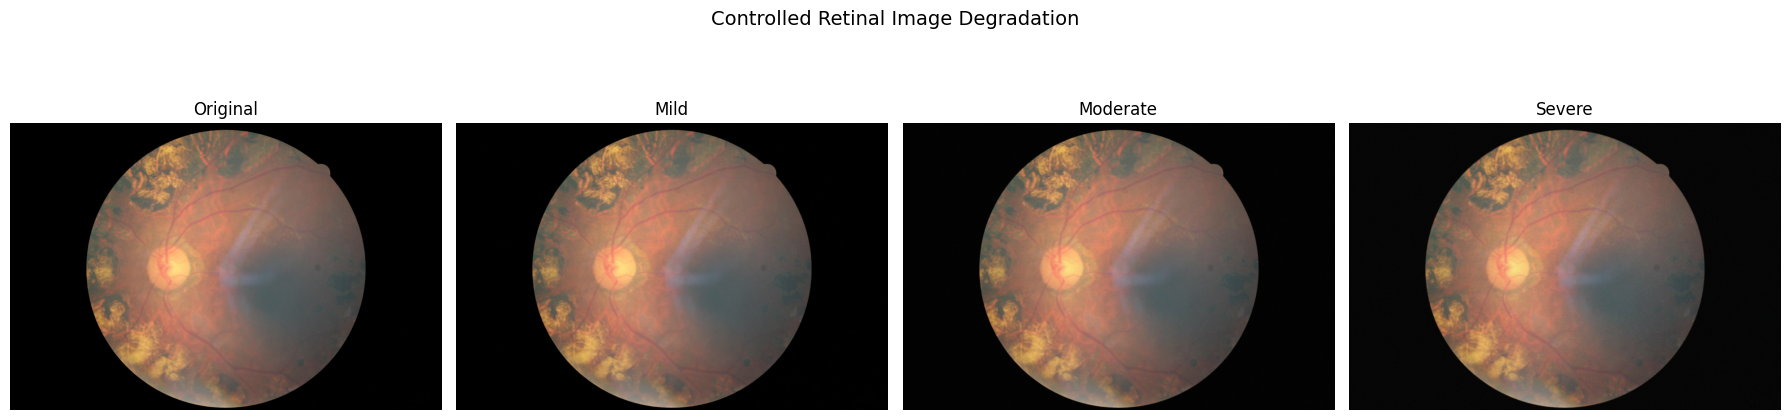

In [13]:
import matplotlib.pyplot as plt
import torch

levels = ["mild", "moderate", "severe"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Original image
axes[0].imshow(sample_image)
axes[0].set_title("Original")
axes[0].axis("off")

# Degraded images
for i, level in enumerate(levels, start=1):

    torch.manual_seed(42)

    degraded = degradation_transforms[level](
        sample_image.copy()
    )

    axes[i].imshow(degraded)
    axes[i].set_title(level.capitalize())
    axes[i].axis("off")

plt.suptitle(
    "Controlled Retinal Image Degradation",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [45]:

# ============================================================
# CELL 81: UPDATED CONTROLLED PAIRED EYEQ DATASET
# Uses revised degradation configuration.
# ============================================================

import random
import torch

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image, ImageOps


class ControlledPairedEyeQDataset(Dataset):

    def __init__(
        self,
        dataframe,
        training=False,
        level=None,
        seed=2026
    ):

        self.dataframe = dataframe.reset_index(drop=True)

        self.training = training
        self.level = level
        self.seed = seed

        self.epoch = 0

        if not training and level not in DEGRADATION_CONFIG:
            raise ValueError(
                "Validation requires a valid degradation level."
            )

        self.resize = transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        )

    def set_epoch(self, epoch):

        self.epoch = epoch

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        original = Image.open(
            row["file_path"]
        ).convert("RGB")

        # Deterministic per-sample random seed
        if self.training:

            sample_seed = (
                self.seed
                + self.epoch * len(self.dataframe)
                + idx
            )

        else:

            sample_seed = self.seed + idx

        local_rng = random.Random(sample_seed)

        # Select degradation level
        if self.training:

            selected_level = local_rng.choice(
                list(DEGRADATION_CONFIG.keys())
            )

        else:

            selected_level = self.level

        # Identical horizontal flip for both images
        if self.training and local_rng.random() < 0.5:

            original = ImageOps.mirror(original)

        # Resize before degradation
        original = self.resize(original)

        # Create degraded paired image
        with torch.random.fork_rng(devices=[]):

            torch.manual_seed(sample_seed)

            degraded = degradation_transforms[
                selected_level
            ](original.copy())

        # Normalize both images consistently
        original_tensor = eval_transform(original)

        degraded_tensor = eval_transform(degraded)

        return {
            "original": original_tensor,
            "degraded": degraded_tensor,
            "label": int(row["DR_grade"]),
            "quality": int(row["quality"]),
            "filename": row["image"],
            "level": selected_level
        }


# ============================================================
# TRAINING DATASET AND DATALOADER
# ============================================================

controlled_train_dataset = ControlledPairedEyeQDataset(
    train_df,
    training=True,
    seed=2026
)

controlled_train_loader = DataLoader(
    controlled_train_dataset,
    batch_size=EXPERIMENT_CONFIG["batch_size"],
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


# ============================================================
# VALIDATION DATASETS AND DATALOADERS
# ============================================================

controlled_val_datasets = {}

controlled_val_loaders = {}

for level in DEGRADATION_CONFIG:

    dataset = ControlledPairedEyeQDataset(
        val_df,
        training=False,
        level=level,
        seed=2026
    )

    controlled_val_datasets[level] = dataset

    controlled_val_loaders[level] = DataLoader(
        dataset,
        batch_size=EXPERIMENT_CONFIG["batch_size"],
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )


# ============================================================
# DATASET SUMMARY
# ============================================================

print("=" * 65)
print("UPDATED PAIRED EYEQ DATASETS")
print("=" * 65)

print("Training samples:", len(controlled_train_dataset))

for level, dataset in controlled_val_datasets.items():

    print(
        f"{level.capitalize()} validation samples:",
        len(dataset)
    )

print("\nEpoch-dependent training randomness: enabled")
print("Deterministic validation: enabled")
print("Resize before degradation: enabled")

print("\nDataset construction completed.")


UPDATED PAIRED EYEQ DATASETS
Training samples: 10010
Mild validation samples: 2533
Moderate validation samples: 2533
Severe validation samples: 2533

Epoch-dependent training randomness: enabled
Deterministic validation: enabled
Resize before degradation: enabled

Dataset construction completed.


In [15]:
# ============================================================
# STEP 3D: VERIFY CONTROLLED PAIRED DATASET
# ============================================================

batch = next(iter(controlled_train_loader))

print("TRAINING BATCH")
print("Original:", batch["original"].shape)
print("Degraded:", batch["degraded"].shape)
print("DR labels:", batch["label"].shape)
print("Quality labels:", batch["quality"].shape)
print("Degradation levels:", batch["level"])

assert batch["original"].shape == batch["degraded"].shape
assert batch["original"].shape[1:] == (3, 224, 224)

# Verify all three validation levels
print("\nVALIDATION REPRODUCIBILITY")

for level, dataset in controlled_val_datasets.items():

    sample_a = dataset[0]
    sample_b = dataset[0]

    assert torch.equal(
        sample_a["original"],
        sample_b["original"]
    )

    assert torch.equal(
        sample_a["degraded"],
        sample_b["degraded"]
    )

    assert sample_a["level"] == level

    print(f"{level.capitalize()}: reproducibility passed")

print("\nAll controlled dataset checks passed.")

TRAINING BATCH
Original: torch.Size([16, 3, 224, 224])
Degraded: torch.Size([16, 3, 224, 224])
DR labels: torch.Size([16])
Quality labels: torch.Size([16])
Degradation levels: ['severe', 'mild', 'moderate', 'moderate', 'mild', 'mild', 'mild', 'moderate', 'mild', 'severe', 'severe', 'mild', 'severe', 'moderate', 'mild', 'moderate']

VALIDATION REPRODUCIBILITY
Mild: reproducibility passed
Moderate: reproducibility passed
Severe: reproducibility passed

All controlled dataset checks passed.


In [16]:

# ============================================================
# STEP 2: VERIFY CORRECTED DEGRADATION PIPELINE
# ============================================================

print("=" * 60)
print("DEGRADATION PIPELINE VERIFICATION")
print("=" * 60)

reference_original = None

for level, dataset in controlled_val_datasets.items():

    sample = dataset[0]
    repeated_sample = dataset[0]

    original = sample["original"]
    degraded = sample["degraded"]

    # 1. Check tensor dimensions
    assert original.shape == (3, 224, 224)
    assert degraded.shape == (3, 224, 224)

    # 2. Check numerical validity
    assert torch.isfinite(original).all()
    assert torch.isfinite(degraded).all()

    # 3. Check reproducibility
    assert torch.equal(
        degraded,
        repeated_sample["degraded"]
    )

    # 4. Measure degradation strength
    difference = torch.abs(original - degraded)

    mean_difference = difference.mean().item()
    max_difference = difference.max().item()

    # 5. Check original image consistency across levels
    if reference_original is None:
        reference_original = original.clone()
    else:
        assert torch.equal(
            reference_original,
            original
        )

    print(f"\n{level.upper()}")
    print("Original shape:", original.shape)
    print("Degraded shape:", degraded.shape)
    print("Mean absolute difference:", round(mean_difference, 6))
    print("Maximum absolute difference:", round(max_difference, 6))
    print("Reproducibility: Passed")

print("\nAll degradation verification checks passed.")


DEGRADATION PIPELINE VERIFICATION

MILD
Original shape: torch.Size([3, 224, 224])
Degraded shape: torch.Size([3, 224, 224])
Mean absolute difference: 0.032002
Maximum absolute difference: 0.599366
Reproducibility: Passed

MODERATE
Original shape: torch.Size([3, 224, 224])
Degraded shape: torch.Size([3, 224, 224])
Mean absolute difference: 0.094397
Maximum absolute difference: 1.284357
Reproducibility: Passed

SEVERE
Original shape: torch.Size([3, 224, 224])
Degraded shape: torch.Size([3, 224, 224])
Mean absolute difference: 0.181023
Maximum absolute difference: 1.866598
Reproducibility: Passed

All degradation verification checks passed.


In [17]:

# ============================================================
# STEP 2: VERIFY CORRECTED DEGRADATION PIPELINE
# ============================================================

print("=" * 60)
print("DEGRADATION PIPELINE VERIFICATION")
print("=" * 60)

reference_original = None

for level, dataset in controlled_val_datasets.items():

    sample = dataset[0]
    repeated_sample = dataset[0]

    original = sample["original"]
    degraded = sample["degraded"]

    # 1. Check tensor dimensions
    assert original.shape == (3, 224, 224)
    assert degraded.shape == (3, 224, 224)

    # 2. Check numerical validity
    assert torch.isfinite(original).all()
    assert torch.isfinite(degraded).all()

    # 3. Check reproducibility
    assert torch.equal(
        degraded,
        repeated_sample["degraded"]
    )

    # 4. Measure degradation strength
    difference = torch.abs(original - degraded)

    mean_difference = difference.mean().item()
    max_difference = difference.max().item()

    # 5. Check original image consistency across levels
    if reference_original is None:
        reference_original = original.clone()
    else:
        assert torch.equal(
            reference_original,
            original
        )

    print(f"\n{level.upper()}")
    print("Original shape:", original.shape)
    print("Degraded shape:", degraded.shape)
    print("Mean absolute difference:", round(mean_difference, 6))
    print("Maximum absolute difference:", round(max_difference, 6))
    print("Reproducibility: Passed")

print("\nAll degradation verification checks passed.")


DEGRADATION PIPELINE VERIFICATION

MILD
Original shape: torch.Size([3, 224, 224])
Degraded shape: torch.Size([3, 224, 224])
Mean absolute difference: 0.032002
Maximum absolute difference: 0.599366
Reproducibility: Passed

MODERATE
Original shape: torch.Size([3, 224, 224])
Degraded shape: torch.Size([3, 224, 224])
Mean absolute difference: 0.094397
Maximum absolute difference: 1.284357
Reproducibility: Passed

SEVERE
Original shape: torch.Size([3, 224, 224])
Degraded shape: torch.Size([3, 224, 224])
Mean absolute difference: 0.181023
Maximum absolute difference: 1.866598
Reproducibility: Passed

All degradation verification checks passed.


In [18]:

# ============================================================
# STEP 3: MULTI-IMAGE DEGRADATION SEVERITY CHECK
# ============================================================

import torch

NUM_SAMPLES = 8

severity_results = {
    "mild": [],
    "moderate": [],
    "severe": []
}

print("MULTI-IMAGE DEGRADATION CHECK")
print("=" * 55)

for idx in range(NUM_SAMPLES):

    for level in ["mild", "moderate", "severe"]:

        sample = controlled_val_datasets[level][idx]

        difference = torch.abs(
            sample["original"] - sample["degraded"]
        )

        severity_results[level].append(
            difference.mean().item()
        )

# Calculate average difference for each severity
averages = {}

for level, values in severity_results.items():

    averages[level] = sum(values) / len(values)

    print(
        f"{level.capitalize()} average difference: "
        f"{averages[level]:.6f}"
    )

print("\nSEVERITY ORDERING")

if (
    averages["mild"]
    < averages["moderate"]
    < averages["severe"]
):
    print("Passed: Mild < Moderate < Severe")
else:
    print("Warning: Severity ordering is not consistent.")

print("\nSamples evaluated:", NUM_SAMPLES)


MULTI-IMAGE DEGRADATION CHECK
Mild average difference: 0.033059
Moderate average difference: 0.098134
Severe average difference: 0.190577

SEVERITY ORDERING
Passed: Mild < Moderate < Severe

Samples evaluated: 8


In [19]:
import torch
import torch.nn.functional as F
import gc

def differentiable_gradcam(model, images, target_layer, labels):
    """
    Grad-CAM that preserves gradients through the CAM calculation.
    Target class: ground-truth DR grade.
    """
    activations = {}

    def forward_hook(module, inputs, output):
        activations["features"] = output

    handle = target_layer.register_forward_hook(forward_hook)

    try:
        logits = model(images)
        features = activations["features"]

        target_scores = logits.gather(
            1, labels.view(-1, 1)
        ).sum()

        gradients = torch.autograd.grad(
            outputs=target_scores,
            inputs=features,
            create_graph=True,
            retain_graph=True
        )[0]

        weights = gradients.mean(
            dim=(2, 3), keepdim=True
        )

        cam = F.relu(
            (weights * features).sum(dim=1, keepdim=True)
        )

        cam = F.interpolate(
            cam,
            size=images.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam / (
            cam.amax(dim=(2, 3), keepdim=True) + 1e-8
        )

        return cam, logits

    finally:
        handle.remove()


# ------------------------------------------------------------
# TEST DIFFERENTIABLE GRAD-CAM ON A SMALL BATCH
# ------------------------------------------------------------

device = EXPERIMENT_DEVICE

test_batch = next(iter(controlled_train_loader))

original = test_batch["original"][:2].to(device)
degraded = test_batch["degraded"][:2].to(device)
labels = test_batch["label"][:2].to(device)

target_layers = {
    "ResNet50": lambda model: model.layer4[-1],
    "ConvNeXt Tiny": lambda model: model.features[-1]
}

for model_name in ["ResNet50", "ConvNeXt Tiny"]:

    print(f"\nTesting {model_name}")

    model = create_experiment_model(model_name)
    model.eval()
    model.zero_grad(set_to_none=True)

    cam_original, logits_original = differentiable_gradcam(
        model, original, target_layers[model_name](model), labels
    )

    cam_degraded, logits_degraded = differentiable_gradcam(
        model, degraded, target_layers[model_name](model), labels
    )

    stability_loss = F.mse_loss(
        cam_original, cam_degraded
    )

    model.zero_grad(set_to_none=True)
    stability_loss.backward()

    gradient_norm = sum(
        parameter.grad.detach().norm().item()
        for parameter in model.parameters()
        if parameter.grad is not None
    )

    print("Original CAM:", cam_original.shape)
    print("Degraded CAM:", cam_degraded.shape)
    print("Stability loss:", stability_loss.item())
    print("Gradient norm:", gradient_norm)

    assert cam_original.shape == cam_degraded.shape
    assert torch.isfinite(stability_loss)
    assert gradient_norm > 0

    print("Differentiable Grad-CAM test: PASSED")

    del model, cam_original, cam_degraded
    del logits_original, logits_degraded
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nAll differentiable Grad-CAM tests passed.")


Testing ResNet50
Original CAM: torch.Size([2, 1, 224, 224])
Degraded CAM: torch.Size([2, 1, 224, 224])
Stability loss: 0.007233073469251394
Gradient norm: 3.997992985532619
Differentiable Grad-CAM test: PASSED

Testing ConvNeXt Tiny
Original CAM: torch.Size([2, 1, 224, 224])
Degraded CAM: torch.Size([2, 1, 224, 224])
Stability loss: 0.0019444369245320559
Gradient norm: 2.185997954074992
Differentiable Grad-CAM test: PASSED

All differentiable Grad-CAM tests passed.


In [20]:
#Determing Stability - Loss weight 
import torch.nn.functional as F
import gc

test_batch = next(iter(controlled_train_loader))

original = test_batch["original"][:2].to(EXPERIMENT_DEVICE)
degraded = test_batch["degraded"][:2].to(EXPERIMENT_DEVICE)
labels = test_batch["label"][:2].to(EXPERIMENT_DEVICE)

target_layers = {
    "ResNet50": lambda model: model.layer4[-1],
    "ConvNeXt Tiny": lambda model: model.features[-1]
}

print("LOSS SCALE DIAGNOSTIC")

for model_name in ["ResNet50", "ConvNeXt Tiny"]:

    model = create_experiment_model(model_name)
    model.eval()

    cam_original, logits_original = differentiable_gradcam(
        model, original, target_layers[model_name](model), labels
    )

    cam_degraded, logits_degraded = differentiable_gradcam(
        model, degraded, target_layers[model_name](model), labels
    )

    classification_loss = (
        F.cross_entropy(logits_original, labels)
        + F.cross_entropy(logits_degraded, labels)
    ) / 2

    stability_loss = F.mse_loss(
        cam_original, cam_degraded
    )

    print(f"\n{model_name}")
    print("Classification loss:", classification_loss.item())
    print("Stability loss:", stability_loss.item())

    for weight in [10, 50, 100]:
        contribution = weight * stability_loss.item()
        print(
            f"Weight {weight}: "
            f"weighted stability={contribution:.6f}, "
            f"relative to classification="
            f"{contribution / classification_loss.item():.4%}"
        )

    del model, cam_original, cam_degraded
    del logits_original, logits_degraded
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nLoss scale diagnostic completed.")

LOSS SCALE DIAGNOSTIC

ResNet50
Classification loss: 1.4855715036392212
Stability loss: 0.0680311769247055
Weight 10: weighted stability=0.680312, relative to classification=45.7946%
Weight 50: weighted stability=3.401559, relative to classification=228.9731%
Weight 100: weighted stability=6.803118, relative to classification=457.9462%

ConvNeXt Tiny
Classification loss: 1.17362380027771
Stability loss: 0.027596769854426384
Weight 10: weighted stability=0.275968, relative to classification=23.5142%
Weight 50: weighted stability=1.379838, relative to classification=117.5708%
Weight 100: weighted stability=2.759677, relative to classification=235.1415%

Loss scale diagnostic completed.


In [21]:
#Comparing Graedient Contribution
import torch
import torch.nn.functional as F
import gc

test_batch = next(iter(controlled_train_loader))

original = test_batch["original"][:2].to(EXPERIMENT_DEVICE)
degraded = test_batch["degraded"][:2].to(EXPERIMENT_DEVICE)
labels = test_batch["label"][:2].to(EXPERIMENT_DEVICE)

target_layers = {
    "ResNet50": lambda model: model.layer4[-1],
    "ConvNeXt Tiny": lambda model: model.features[-1]
}

def global_gradient_norm(gradients):
    squared_norm = sum(
        gradient.detach().pow(2).sum()
        for gradient in gradients
        if gradient is not None
    )
    return squared_norm.sqrt().item()

print("GRADIENT CONTRIBUTION DIAGNOSTIC")

for model_name in ["ResNet50", "ConvNeXt Tiny"]:

    model = create_experiment_model(model_name)
    model.eval()

    parameters = [
        parameter for parameter in model.parameters()
        if parameter.requires_grad
    ]

    cam_original, logits_original = differentiable_gradcam(
        model, original, target_layers[model_name](model), labels
    )

    cam_degraded, logits_degraded = differentiable_gradcam(
        model, degraded, target_layers[model_name](model), labels
    )

    classification_loss = (
        F.cross_entropy(logits_original, labels)
        + F.cross_entropy(logits_degraded, labels)
    ) / 2

    stability_loss = F.mse_loss(
        cam_original, cam_degraded
    )

    classification_gradients = torch.autograd.grad(
        classification_loss,
        parameters,
        retain_graph=True,
        allow_unused=True
    )

    stability_gradients = torch.autograd.grad(
        stability_loss,
        parameters,
        allow_unused=True
    )

    classification_norm = global_gradient_norm(
        classification_gradients
    )

    stability_norm = global_gradient_norm(
        stability_gradients
    )

    print(f"\n{model_name}")
    print("Classification gradient norm:", classification_norm)
    print("Stability gradient norm:", stability_norm)

    for weight in [100, 250, 500]:
        ratio = (
            weight * stability_norm /
            (classification_norm + 1e-12)
        )
        print(
            f"Weight {weight}: stability/classification "
            f"gradient ratio = {ratio:.4f}"
        )

    del model, cam_original, cam_degraded
    del logits_original, logits_degraded
    del classification_gradients, stability_gradients
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nGradient diagnostic completed.")

GRADIENT CONTRIBUTION DIAGNOSTIC

ResNet50
Classification gradient norm: 75.66605377197266
Stability gradient norm: 2.2526919841766357
Weight 100: stability/classification gradient ratio = 2.9772
Weight 250: stability/classification gradient ratio = 7.4429
Weight 500: stability/classification gradient ratio = 14.8858

ConvNeXt Tiny
Classification gradient norm: 37.69514465332031
Stability gradient norm: 2.6244122982025146
Weight 100: stability/classification gradient ratio = 6.9622
Weight 250: stability/classification gradient ratio = 17.4055
Weight 500: stability/classification gradient ratio = 34.8110

Gradient diagnostic completed.


In [22]:
#testing GRAD CAM reproducibility
import torch
import torch.nn.functional as F
import gc

# Use fixed validation samples rather than shuffled training batches
sample_a = controlled_val_datasets["moderate"][0]
sample_b = controlled_val_datasets["moderate"][1]

original = torch.stack([
    sample_a["original"],
    sample_b["original"]
]).to(EXPERIMENT_DEVICE)

degraded = torch.stack([
    sample_a["degraded"],
    sample_b["degraded"]
]).to(EXPERIMENT_DEVICE)

labels = torch.tensor([
    sample_a["label"],
    sample_b["label"]
], dtype=torch.long, device=EXPERIMENT_DEVICE)

target_layers = {
    "ResNet50": lambda model: model.layer4[-1],
    "ConvNeXt Tiny": lambda model: model.features[-1]
}

print("FIXED-BATCH GRAD-CAM REPRODUCIBILITY")

for model_name in ["ResNet50", "ConvNeXt Tiny"]:

    model = create_experiment_model(model_name)
    model.eval()

    cam_results = []

    for repeat in range(3):
        cam_original, _ = differentiable_gradcam(
            model, original, target_layers[model_name](model), labels
        )

        cam_degraded, _ = differentiable_gradcam(
            model, degraded, target_layers[model_name](model), labels
        )

        loss = F.mse_loss(cam_original, cam_degraded)
        cam_results.append(loss.item())

        print(f"{model_name} | Repeat {repeat + 1}: {loss.item():.8f}")

    difference = max(cam_results) - min(cam_results)

    print("Maximum difference:", difference)
    print("Reproducible:", difference < 1e-7)

    del model, cam_original, cam_degraded
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nReproducibility test completed.")

FIXED-BATCH GRAD-CAM REPRODUCIBILITY
ResNet50 | Repeat 1: 0.01794701
ResNet50 | Repeat 2: 0.01794701
ResNet50 | Repeat 3: 0.01794701
Maximum difference: 0.0
Reproducible: True
ConvNeXt Tiny | Repeat 1: 0.04757639
ConvNeXt Tiny | Repeat 2: 0.04757639
ConvNeXt Tiny | Repeat 3: 0.04757639
Maximum difference: 0.0
Reproducible: True

Reproducibility test completed.


In [23]:

# ============================================================
# STEP 4A: EXPERIMENT CLASS WEIGHT CONFIGURATION
# ============================================================

# Reuse class weights calculated from training data.
# These were originally defined in the baseline configuration.

EXPERIMENT_CLASS_WEIGHTS = (
    class_weights.detach()
    .clone()
    .to(EXPERIMENT_DEVICE)
)

print("EXPERIMENT CLASS WEIGHTS")
print("=" * 45)

print(
    "Class weights:",
    EXPERIMENT_CLASS_WEIGHTS.cpu().numpy()
)

print("Number of classes:", len(EXPERIMENT_CLASS_WEIGHTS))
print("Device:", EXPERIMENT_CLASS_WEIGHTS.device)

# Verify configuration
assert len(EXPERIMENT_CLASS_WEIGHTS) == 5
assert torch.isfinite(EXPERIMENT_CLASS_WEIGHTS).all()
assert (EXPERIMENT_CLASS_WEIGHTS > 0).all()

# Confirm original baseline weights remain unchanged
assert torch.equal(
    EXPERIMENT_CLASS_WEIGHTS.cpu(),
    class_weights.cpu()
)

print("\nClass-weight configuration verified.")


EXPERIMENT CLASS WEIGHTS
Class weights: [0.27083334 2.8078542  1.3912439  7.670498   9.765854  ]
Number of classes: 5
Device: cuda:0

Class-weight configuration verified.


In [24]:
#Calibrating final training configuration
import torch
import torch.nn.functional as F
import gc

# Fixed validation samples
samples = [
    controlled_val_datasets["moderate"][0],
    controlled_val_datasets["moderate"][1]
]

original = torch.stack([s["original"] for s in samples]).to(EXPERIMENT_DEVICE)
degraded = torch.stack([s["degraded"] for s in samples]).to(EXPERIMENT_DEVICE)
labels = torch.tensor(
    [s["label"] for s in samples],
    dtype=torch.long,
    device=EXPERIMENT_DEVICE
)

target_layers = {
    "ResNet50": lambda model: model.layer4[-1],
    "ConvNeXt Tiny": lambda model: model.features[-1]
}

def calculate_gradient_norm(grads):
    return torch.sqrt(sum(
        g.detach().pow(2).sum()
        for g in grads if g is not None
    )).item()

print("FINAL CONFIGURATION GRADIENT CALIBRATION")

for model_name in ["ResNet50", "ConvNeXt Tiny"]:

    model = create_experiment_model(model_name)

    parameters = [
        p for p in model.parameters() if p.requires_grad
    ]

    # Classification objective: training mode
    model.train()

    logits_original_train = model(original)
    logits_degraded_train = model(degraded)

    
    classification_loss = (
        F.cross_entropy(
            logits_original_train,
            labels,
            weight=EXPERIMENT_CLASS_WEIGHTS
        )
        + F.cross_entropy(
            logits_degraded_train,
            labels,
            weight=EXPERIMENT_CLASS_WEIGHTS
        )
    ) / 2.0


    # Explanation objective: evaluation mode, gradients retained
    model.eval()

    cam_original, _ = differentiable_gradcam(
        model, original, target_layers[model_name](model), labels
    )

    cam_degraded, _ = differentiable_gradcam(
        model, degraded, target_layers[model_name](model), labels
    )

    stability_loss = F.mse_loss(cam_original, cam_degraded)

    classification_grads = torch.autograd.grad(
        classification_loss,
        parameters,
        retain_graph=True,
        allow_unused=True
    )

    stability_grads = torch.autograd.grad(
        stability_loss,
        parameters,
        allow_unused=True
    )

    classification_norm = calculate_gradient_norm(classification_grads)
    stability_norm = calculate_gradient_norm(stability_grads)

    print(f"\n{model_name}")
    print("Classification loss:", classification_loss.item())
    print("Stability loss:", stability_loss.item())
    print("Classification gradient norm:", classification_norm)
    print("Stability gradient norm:", stability_norm)

    for weight in [100, 250, 500]:
        ratio = (
            weight * stability_norm /
            (classification_norm + 1e-12)
        )
        print(f"Weight {weight}: gradient ratio = {ratio:.4f}")

    del model, cam_original, cam_degraded
    del logits_original_train, logits_degraded_train
    del classification_grads, stability_grads
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nFinal calibration completed.")

FINAL CONFIGURATION GRADIENT CALIBRATION

ResNet50
Classification loss: 3.3924522399902344
Stability loss: 0.016360707581043243
Classification gradient norm: 26.90859031677246
Stability gradient norm: 3.2315919399261475
Weight 100: gradient ratio = 12.0095
Weight 250: gradient ratio = 30.0238
Weight 500: gradient ratio = 60.0476

ConvNeXt Tiny
Classification loss: 2.843411922454834
Stability loss: 0.04757639393210411
Classification gradient norm: 83.50562286376953
Stability gradient norm: 2.9505503177642822
Weight 100: gradient ratio = 3.5334
Weight 250: gradient ratio = 8.8334
Weight 500: gradient ratio = 17.6668

Final calibration completed.


In [25]:

# Defining the training function

def train_stability_aware_epoch(
    model,
    loader,
    optimizer,
    model_name,
    lambda_stability,
    cam_batch_size=2,
    epoch=0,
    max_batches=None,
    max_grad_norm=1.0
):
    """
    Stability-aware training:
    1. Classification on original and degraded images.
    2. Grad-CAM consistency in evaluation mode.
    3. Combined gradients with gradient clipping.
    """

    # Change the training degradation/augmentation seed before creating the iterator.
    if hasattr(loader.dataset, "set_epoch"):
        loader.dataset.set_epoch(epoch)

    target_layer = (
        model.layer4[-1]
        if model_name == "ResNet50"
        else model.features[-1]
    )

    model.train()

    total_classification_loss = 0.0
    total_stability_loss = 0.0
    total_accuracy = 0.0
    total_gradient_norm = 0.0
    processed_batches = 0

    for batch_index, batch in enumerate(loader):

        if max_batches is not None and batch_index >= max_batches:
            break

        original = batch["original"].to(
            EXPERIMENT_DEVICE, non_blocking=True
        )
        degraded = batch["degraded"].to(
            EXPERIMENT_DEVICE, non_blocking=True
        )
        labels = batch["label"].to(
            EXPERIMENT_DEVICE, non_blocking=True
        ).long()

        optimizer.zero_grad(set_to_none=True)

        # PART 1: Classification training
        model.train()

        logits_original = model(original)
        logits_degraded = model(degraded)

        loss_original = F.cross_entropy(
            logits_original,
            labels,
            weight=EXPERIMENT_CLASS_WEIGHTS
        )

        loss_degraded = F.cross_entropy(
            logits_degraded,
            labels,
            weight=EXPERIMENT_CLASS_WEIGHTS
        )

        classification_loss = (
            loss_original + loss_degraded
        ) / 2.0

        # Backpropagate classification gradients first.
        classification_loss.backward()

        # PART 2: Grad-CAM consistency
        # Evaluation mode makes CAM calculations deterministic.
        # Autograd remains enabled.

        model.eval()

        batch_size = original.size(0)
        stability_loss_sum = 0.0

        for start in range(0, batch_size, cam_batch_size):

            end = min(start + cam_batch_size, batch_size)

            original_chunk = original[start:end]
            degraded_chunk = degraded[start:end]
            label_chunk = labels[start:end]

            cam_original, _ = differentiable_gradcam(
                model,
                original_chunk,
                target_layer,
                label_chunk
            )

            cam_degraded, _ = differentiable_gradcam(
                model,
                degraded_chunk,
                target_layer,
                label_chunk
            )

            stability_loss = F.mse_loss(
                cam_original,
                cam_degraded
            )

            # Scale each chunk to obtain the batch-average objective.
            chunk_weight = (end - start) / batch_size

            (
                lambda_stability
                * chunk_weight
                * stability_loss
            ).backward()

            stability_loss_sum += (
                stability_loss.detach().item() * chunk_weight
            )

            del cam_original, cam_degraded, stability_loss

        # PART 3: Optimizer update
        model.train()

        gradient_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_grad_norm
        )

        optimizer.step()

        # PART 4: Metrics
        predictions = logits_original.argmax(dim=1)

        accuracy = (
            predictions == labels
        ).float().mean().item()

        total_classification_loss += classification_loss.item()
        total_stability_loss += stability_loss_sum
        total_accuracy += accuracy
        total_gradient_norm += gradient_norm.item()

        processed_batches += 1

    if processed_batches == 0:
        raise ValueError("No training batches were processed.")

    average_classification = (
        total_classification_loss / processed_batches
    )

    average_stability = (
        total_stability_loss / processed_batches
    )

    return {
        "classification_loss": average_classification,
        "stability_loss": average_stability,
        "total_loss": (
            average_classification
            + lambda_stability * average_stability
        ),
        "accuracy": total_accuracy / processed_batches,
        "gradient_norm_before_clipping": (
            total_gradient_norm / processed_batches
        ),
        "batches_processed": processed_batches
    }


print("Stability-aware training function defined successfully.")


Stability-aware training function defined successfully.


In [26]:
#Preparing fair experimental data loading 

from torch.utils.data import DataLoader

EXPERIMENT_SEED = 42

def make_experiment_train_loader(seed=EXPERIMENT_SEED):
    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        controlled_train_dataset,
        batch_size=EXPERIMENT_CONFIG["batch_size"],
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        generator=generator,
        drop_last=False
    )


# Create two independent loaders with the same seed.
loader_check_a = make_experiment_train_loader()
loader_check_b = make_experiment_train_loader()

batch_a = next(iter(loader_check_a))
batch_b = next(iter(loader_check_b))

filenames_a = batch_a["filename"]
filenames_b = batch_b["filename"]

print("DETERMINISTIC LOADER VERIFICATION")
print("=" * 45)

print("Training samples:", len(controlled_train_dataset))
print("Batches per epoch:", len(loader_check_a))
print("Batch size:", EXPERIMENT_CONFIG["batch_size"])

print("\nFirst 8 filenames:")
print(filenames_a[:8])

print("\nSame first batch:", filenames_a == filenames_b)
print("Same labels:", torch.equal(batch_a["label"], batch_b["label"]))
print(
    "Same original images:",
    torch.equal(batch_a["original"], batch_b["original"])
)
print(
    "Same degraded images:",
    torch.equal(batch_a["degraded"], batch_b["degraded"])
)

assert filenames_a == filenames_b
assert torch.equal(batch_a["label"], batch_b["label"])
assert torch.equal(batch_a["original"], batch_b["original"])
assert torch.equal(batch_a["degraded"], batch_b["degraded"])

print("\nDeterministic data loading verified.")


DETERMINISTIC LOADER VERIFICATION
Training samples: 10010
Batches per epoch: 626
Batch size: 16

First 8 filenames:
['40757_right.jpeg', '42122_left.jpeg', '37892_left.jpeg', '29524_left.jpeg', '37488_left.jpeg', '13395_left.jpeg', '38356_right.jpeg', '21065_left.jpeg']

Same first batch: True
Same labels: True
Same original images: True
Same degraded images: True

Deterministic data loading verified.


In [27]:
#Implementing standard and Degradation - aware training 

def train_classification_strategy_epoch(
    model,
    loader,
    optimizer,
    strategy,
    epoch=0,
    max_batches=None,
    max_grad_norm=1.0
):
    """
    Standard:
        CE(original, label)

    Degradation-aware:
        [CE(original, label) + CE(degraded, label)] / 2
    """

    if strategy not in ["standard", "degradation_aware"]:
        raise ValueError(f"Unsupported strategy: {strategy}")

    # Ensure each epoch receives its reproducible degradation variation.
    if hasattr(loader.dataset, "set_epoch"):
        loader.dataset.set_epoch(epoch)

    model.train()

    total_loss = 0.0
    total_accuracy = 0.0
    total_gradient_norm = 0.0
    processed_batches = 0

    for batch_index, batch in enumerate(loader):

        if max_batches is not None and batch_index >= max_batches:
            break

        original = batch["original"].to(
            EXPERIMENT_DEVICE, non_blocking=True
        )
        degraded = batch["degraded"].to(
            EXPERIMENT_DEVICE, non_blocking=True
        )
        labels = batch["label"].to(
            EXPERIMENT_DEVICE, non_blocking=True
        ).long()

        optimizer.zero_grad(set_to_none=True)

        # Original-image classification
        logits_original = model(original)
        loss_original = F.cross_entropy(
            logits_original,
            labels,
            weight=EXPERIMENT_CLASS_WEIGHTS
        )


        if strategy == "standard":
            loss = loss_original

        else:
            # Additional classification on degraded images
            logits_degraded = model(degraded)
            loss_degraded = F.cross_entropy(
                logits_degraded, 
                labels,
                weight=EXPERIMENT_CLASS_WEIGHTS
            )

            loss = (loss_original + loss_degraded) / 2.0

        loss.backward()

        gradient_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_grad_norm
        )

        optimizer.step()

        predictions = logits_original.argmax(dim=1)
        accuracy = (
            predictions == labels
        ).float().mean().item()

        total_loss += loss.item()
        total_accuracy += accuracy
        total_gradient_norm += gradient_norm.item()

        processed_batches += 1

    if processed_batches == 0:
        raise ValueError("No training batches were processed.")

    return {
        "classification_loss": total_loss / processed_batches,
        "accuracy": total_accuracy / processed_batches,
        "gradient_norm_before_clipping": (
            total_gradient_norm / processed_batches
        ),
        "batches_processed": processed_batches
    }


print("Standard and degradation-aware training functions defined.")


Standard and degradation-aware training functions defined.


In [28]:
#Implementing validation function

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
from torch.utils.data import DataLoader
import numpy as np
import gc

def evaluate_dr_condition(model, dataset, image_key="original"):
    """
    Evaluate DR grading on original or degraded retinal images.
    Returns accuracy, macro F1, and per-class F1.
    """

    loader = DataLoader(
        dataset,
        batch_size=EXPERIMENT_CONFIG["batch_size"],
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for batch in loader:

            images = batch[image_key].to(
                EXPERIMENT_DEVICE,
                non_blocking=True
            )

            labels = batch["label"].to(
                EXPERIMENT_DEVICE,
                non_blocking=True
            ).long()

            logits = model(images)
            predictions = logits.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_predictions)

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2, 3, 4],
        average="macro",
        zero_division=0
    )

    class_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=[0, 1, 2, 3, 4],
        average=None,
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "class_f1": class_f1.tolist(),
        "predictions": all_predictions,
        "labels": all_labels
    }


def evaluate_all_conditions(model):

    results = {}

    # Original images: use one validation dataset's original images.
    results["original"] = evaluate_dr_condition(
        model,
        controlled_val_datasets["mild"],
        image_key="original"
    )

    # Degraded images at each controlled severity.
    for level in ["mild", "moderate", "severe"]:

        results[level] = evaluate_dr_condition(
            model,
            controlled_val_datasets[level],
            image_key="degraded"
        )

    return results


print("Validation functions defined successfully.")


Validation functions defined successfully.


In [32]:
# ============================================================
# STEP 5A: FINAL STABILITY WEIGHT CONFIGURATION
# Uses the latest gradient calibration results from Cell 65.
# ============================================================

TARGET_GRADIENT_RATIO = 0.23

# Latest gradient norms from Cell 65
CALIBRATION_GRADIENTS = {
    "ResNet50": {
        "classification": 26.90859031677246,
        "stability": 3.2315919399261475
    },

    "ConvNeXt Tiny": {
        "classification": 83.50562286376953,
        "stability": 2.9505503177642822
    }
}

# Calculate lambda for each architecture
LAMBDA_CONFIG = {
    model_name: (
        TARGET_GRADIENT_RATIO
        * values["classification"]
        / values["stability"]
    )
    for model_name, values in CALIBRATION_GRADIENTS.items()
}

print("FINAL STABILITY WEIGHT CONFIGURATION")
print("=" * 45)

for model_name, value in LAMBDA_CONFIG.items():
    print(f"{model_name}: {value:.4f}")

print("\nTarget gradient contribution:", TARGET_GRADIENT_RATIO)

# Verification
assert set(LAMBDA_CONFIG.keys()) == {
    "ResNet50",
    "ConvNeXt Tiny"
}

assert all(
    value > 0 and np.isfinite(value)
    for value in LAMBDA_CONFIG.values()
)

print("\nStability weight configuration verified.")

FINAL STABILITY WEIGHT CONFIGURATION
ResNet50: 1.9151
ConvNeXt Tiny: 6.5094

Target gradient contribution: 0.23

Stability weight configuration verified.


**A Test of Main Experimental Runner**# # # 

In [34]:

# ============================================================
# STEP 5B: MAIN EXPERIMENT RUNNER - SMOKE TEST
# Tests all 6 combinations with 1 training batch each.
# This is NOT the final training run.
# ============================================================

import random
import gc
import numpy as np
import torch
from torch.utils.data import Subset

# ------------------------------------------------------------
# 1. SMOKE TEST CONFIGURATION
# ------------------------------------------------------------

SMOKE_TEST_BATCHES = 1
SMOKE_VALIDATION_SAMPLES = 128

SMOKE_RESULTS = {}

EXPECTED_ARCHITECTURES = [
    "ResNet50",
    "ConvNeXt Tiny"
]

EXPECTED_STRATEGIES = [
    "standard",
    "degradation_aware",
    "stability_aware"
]

# Verify experiment configuration
assert EXPERIMENT_CONFIG["architectures"] == EXPECTED_ARCHITECTURES
assert EXPERIMENT_CONFIG["strategies"] == EXPECTED_STRATEGIES

assert set(LAMBDA_CONFIG.keys()) == set(EXPECTED_ARCHITECTURES)

# ------------------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------------------

def set_experiment_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ------------------------------------------------------------
# 3. SINGLE EXPERIMENT SMOKE TEST
# ------------------------------------------------------------

def run_experiment_smoke_test(model_name, strategy):

    print("\n" + "=" * 65)
    print(f"ARCHITECTURE: {model_name}")
    print(f"STRATEGY: {strategy}")
    print("=" * 65)

    # Reset random state before each experiment
    set_experiment_seed(EXPERIMENT_SEED)

    # Start from the verified baseline checkpoint
    model = create_experiment_model(model_name)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=EXPERIMENT_CONFIG["learning_rate"],
        weight_decay=EXPERIMENT_CONFIG["weight_decay"]
    )

    # Reproducible training loader
    train_loader = make_experiment_train_loader(
        seed=EXPERIMENT_SEED
    )

    # --------------------------------------------------------
    # ONE-BATCH TRAINING TEST
    # --------------------------------------------------------

    if strategy == "stability_aware":

        train_metrics = train_stability_aware_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            model_name=model_name,
            lambda_stability=LAMBDA_CONFIG[model_name],
            cam_batch_size=2,
            epoch=0,
            max_batches=SMOKE_TEST_BATCHES
        )

    else:

        train_metrics = train_classification_strategy_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            strategy=strategy,
            epoch=0,
            max_batches=SMOKE_TEST_BATCHES
        )

    # --------------------------------------------------------
    # QUICK VALIDATION
    # Diagnostic subset only; not final evaluation.
    # --------------------------------------------------------

    quick_val_results = {}

    for level in ["mild", "moderate", "severe"]:

        quick_dataset = Subset(
            controlled_val_datasets[level],
            range(
                min(
                    SMOKE_VALIDATION_SAMPLES,
                    len(controlled_val_datasets[level])
                )
            )
        )

        # Original-image evaluation
        if level == "mild":

            quick_val_results["original"] = evaluate_dr_condition(
                model,
                quick_dataset,
                image_key="original"
            )

        # Degraded-image evaluation
        quick_val_results[level] = evaluate_dr_condition(
            model,
            quick_dataset,
            image_key="degraded"
        )

    # --------------------------------------------------------
    # VALIDATION CHECKS
    # --------------------------------------------------------

    expected_conditions = {
        "original",
        "mild",
        "moderate",
        "severe"
    }

    assert set(quick_val_results.keys()) == expected_conditions

    for condition, metrics in quick_val_results.items():

        assert np.isfinite(metrics["accuracy"]), (
            f"Invalid accuracy: {model_name}, {strategy}, {condition}"
        )

        assert np.isfinite(metrics["macro_f1"]), (
            f"Invalid Macro F1: {model_name}, {strategy}, {condition}"
        )

    assert train_metrics["batches_processed"] == SMOKE_TEST_BATCHES

    # --------------------------------------------------------
    # SAVE RESULTS IN MEMORY
    # --------------------------------------------------------

    result = {
        "architecture": model_name,
        "strategy": strategy,
        "lambda_stability": (
            LAMBDA_CONFIG[model_name]
            if strategy == "stability_aware"
            else None
        ),
        "training": train_metrics,
        "validation": {
            condition: {
                "accuracy": metrics["accuracy"],
                "macro_f1": metrics["macro_f1"]
            }
            for condition, metrics in quick_val_results.items()
        }
    }

    # --------------------------------------------------------
    # DISPLAY RESULTS
    # --------------------------------------------------------

    print("\nTRAINING RESULTS")

    for key, value in train_metrics.items():
        print(f"{key}: {value}")

    print("\nQUICK VALIDATION RESULTS")

    for condition, metrics in result["validation"].items():

        print(
            f"{condition}: "
            f"Accuracy={metrics['accuracy']:.4f}, "
            f"Macro F1={metrics['macro_f1']:.4f}"
        )

    print("\nExperiment smoke test passed.")

    # --------------------------------------------------------
    # CLEANUP
    # --------------------------------------------------------

    del model
    del optimizer
    del train_loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# ------------------------------------------------------------
# 4. RUN ALL SIX COMBINATIONS
# ------------------------------------------------------------

for model_name in EXPECTED_ARCHITECTURES:

    for strategy in EXPECTED_STRATEGIES:

        key = (model_name, strategy)

        SMOKE_RESULTS[key] = run_experiment_smoke_test(
            model_name,
            strategy
        )


# ------------------------------------------------------------
# 5. FINAL SMOKE TEST VERIFICATION
# ------------------------------------------------------------

assert len(SMOKE_RESULTS) == 6

assert all(
    result["training"]["batches_processed"] == 1
    for result in SMOKE_RESULTS.values()
)

assert all(
    set(result["validation"].keys()) == {
        "original", "mild", "moderate", "severe"
    }
    for result in SMOKE_RESULTS.values()
)

print("\n" + "=" * 65)
print("MAIN EXPERIMENT SMOKE TEST COMPLETED")
print("=" * 65)

print("Architectures tested:", len(EXPECTED_ARCHITECTURES))
print("Strategies tested:", len(EXPECTED_STRATEGIES))
print("Total combinations:", len(SMOKE_RESULTS))
print("Training batches per combination:", SMOKE_TEST_BATCHES)
print("Validation conditions per combination:", 4)

print("\nStatus: ALL SIX COMBINATIONS PASSED")
print("No final checkpoints were selected or saved.")

print("\nNOTE:")
print("Quick validation scores are diagnostic only.")
print("Full validation will be performed during final training.")



ARCHITECTURE: ResNet50
STRATEGY: standard

TRAINING RESULTS
classification_loss: 0.5169196128845215
accuracy: 0.6875
gradient_norm_before_clipping: 5.508831024169922
batches_processed: 1

QUICK VALIDATION RESULTS
original: Accuracy=0.6953, Macro F1=0.4331
mild: Accuracy=0.4062, Macro F1=0.2674
moderate: Accuracy=0.0156, Macro F1=0.0075
severe: Accuracy=0.0078, Macro F1=0.0031

Experiment smoke test passed.

ARCHITECTURE: ResNet50
STRATEGY: degradation_aware

TRAINING RESULTS
classification_loss: 1.3526545763015747
accuracy: 0.6875
gradient_norm_before_clipping: 13.307171821594238
batches_processed: 1

QUICK VALIDATION RESULTS
original: Accuracy=0.6953, Macro F1=0.4402
mild: Accuracy=0.3516, Macro F1=0.2494
moderate: Accuracy=0.0391, Macro F1=0.0197
severe: Accuracy=0.0312, Macro F1=0.0160

Experiment smoke test passed.

ARCHITECTURE: ResNet50
STRATEGY: stability_aware

TRAINING RESULTS
classification_loss: 1.3526545763015747
stability_loss: 0.04680382495280355
total_loss: 1.4422908125

In [49]:

# ============================================================
# STEP 5C: FULL VALIDATION DEGRADATION DIAGNOSTIC
# Evaluates baseline checkpoints before experimental training.
# No model training or checkpoint modification.
# ============================================================

from collections import Counter
import numpy as np
import torch
import gc

CLASS_NAMES = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]

BASELINE_DIAGNOSTIC_RESULTS = {}

print("=" * 70)
print("FULL VALIDATION DEGRADATION DIAGNOSTIC")
print("=" * 70)

# ------------------------------------------------------------
# 1. VALIDATION LABEL DISTRIBUTION
# ------------------------------------------------------------

validation_labels = [
    int(controlled_val_datasets["mild"][i]["label"])
    for i in range(len(controlled_val_datasets["mild"]))
]

print("\nVALIDATION LABEL DISTRIBUTION")

label_counts = Counter(validation_labels)

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name}: "
        f"{label_counts.get(class_id, 0)}"
    )

# ------------------------------------------------------------
# 2. EVALUATE VERIFIED BASELINE CHECKPOINTS
# ------------------------------------------------------------

for model_name in ["ResNet50", "ConvNeXt Tiny"]:

    print("\n" + "=" * 70)
    print("ARCHITECTURE:", model_name)
    print("=" * 70)

    model = create_experiment_model(model_name)
    model.eval()

    results = evaluate_all_conditions(model)

    BASELINE_DIAGNOSTIC_RESULTS[model_name] = results

    # --------------------------------------------------------
    # 3. REPORT METRICS AND PREDICTION DISTRIBUTION
    # --------------------------------------------------------

    for condition in ["original", "mild", "moderate", "severe"]:

        metrics = results[condition]

        predictions = metrics["predictions"]
        predictions = np.asarray(predictions)

        prediction_counts = Counter(predictions.tolist())

        print(f"\nCondition: {condition}")

        print(f"Accuracy: {metrics['accuracy']:.4f}")
        print(f"Macro F1: {metrics['macro_f1']:.4f}")

        print("Prediction distribution:")

        for class_id, class_name in enumerate(CLASS_NAMES):
            print(
                f"  {class_name}: "
                f"{prediction_counts.get(class_id, 0)}"
            )

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 4. FINAL DIAGNOSTIC SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("BASELINE DEGRADATION DIAGNOSTIC COMPLETED")
print("=" * 70)

for model_name, results in BASELINE_DIAGNOSTIC_RESULTS.items():

    print(f"\n{model_name}")

    for condition in ["original", "mild", "moderate", "severe"]:

        print(
            f"{condition:10s} | "
            f"Accuracy: {results[condition]['accuracy']:.4f} | "
            f"Macro F1: {results[condition]['macro_f1']:.4f}"
        )

print("\nNo training was performed.")
print("No baseline checkpoints were modified.")


FULL VALIDATION DEGRADATION DIAGNOSTIC

VALIDATION LABEL DISTRIBUTION
No DR: 1847
Mild: 198
Moderate: 370
Severe: 72
Proliferative: 46

ARCHITECTURE: ResNet50

Condition: original
Accuracy: 0.6747
Macro F1: 0.4709
Prediction distribution:
  No DR: 1688
  Mild: 225
  Moderate: 488
  Severe: 62
  Proliferative: 70

Condition: mild
Accuracy: 0.5705
Macro F1: 0.4169
Prediction distribution:
  No DR: 1354
  Mild: 360
  Moderate: 630
  Severe: 62
  Proliferative: 127

Condition: moderate
Accuracy: 0.3407
Macro F1: 0.2328
Prediction distribution:
  No DR: 769
  Mild: 177
  Moderate: 792
  Severe: 110
  Proliferative: 685

Condition: severe
Accuracy: 0.1003
Macro F1: 0.0759
Prediction distribution:
  No DR: 223
  Mild: 9
  Moderate: 163
  Severe: 27
  Proliferative: 2111

ARCHITECTURE: ConvNeXt Tiny

Condition: original
Accuracy: 0.7008
Macro F1: 0.4949
Prediction distribution:
  No DR: 1774
  Mild: 335
  Moderate: 351
  Severe: 40
  Proliferative: 33

Condition: mild
Accuracy: 0.6775
Macro F1

In [46]:

# ============================================================
# STEP 5D: POST-RESIZE DEGRADATION VALIDATION
# Measures degradation at the actual model input resolution.
# ============================================================

import torch
import pandas as pd
import numpy as np
from PIL import Image
from torchvision import transforms
from torchvision.transforms import functional as TF

IMAGE_SIZE = 224

resize_transform = transforms.Resize(
    (IMAGE_SIZE, IMAGE_SIZE)
)

QUALITY_NAMES = {
    0: "Good",
    1: "Usable",
    2: "Reject"
}

# Sample 5 validation images from each quality category
sample_df = (
    val_df.groupby("quality", group_keys=False)
    .sample(n=5, random_state=42)
)

post_resize_results = []

print("=" * 65)
print("POST-RESIZE DEGRADATION VALIDATION")
print("=" * 65)

for _, row in sample_df.iterrows():

    image = Image.open(
        row["file_path"]
    ).convert("RGB")

    # IMPORTANT: Resize BEFORE degradation,
    # matching ControlledPairedEyeQDataset.
    image = resize_transform(image)

    original_tensor = TF.to_tensor(image)

    for level in ["mild", "moderate", "severe"]:

        # Same deterministic noise seed for comparison
        with torch.random.fork_rng(devices=[]):

            torch.manual_seed(42)

            degraded_image = degradation_transforms[level](
                image.copy()
            )

        degraded_tensor = TF.to_tensor(degraded_image)

        difference = original_tensor - degraded_tensor

        mae = difference.abs().mean().item()

        mse = (difference ** 2).mean().item()

        rmse = np.sqrt(mse)

        psnr = (
            float("inf")
            if mse == 0
            else 20 * np.log10(1.0 / rmse)
        )

        post_resize_results.append({
            "quality": int(row["quality"]),
            "quality_name": QUALITY_NAMES[int(row["quality"])],
            "level": level,
            "MAE": mae,
            "RMSE": rmse,
            "PSNR": psnr
        })

results_df = pd.DataFrame(post_resize_results)

summary = (
    results_df.groupby("level")[["MAE", "RMSE", "PSNR"]]
    .mean()
    .reindex(["mild", "moderate", "severe"])
)

print("\nAVERAGE METRICS AT 224 x 224")
display(summary.round(5))

print("\nMETRICS BY ORIGINAL EYEQ QUALITY")
quality_summary = (
    results_df.groupby(
        ["quality_name", "level"]
    )[["MAE", "RMSE", "PSNR"]]
    .mean()
)

display(quality_summary.round(5))

# Verify expected severity ordering
assert (
    summary.loc["mild", "MAE"]
    < summary.loc["moderate", "MAE"]
    < summary.loc["severe", "MAE"]
)

assert (
    summary.loc["mild", "RMSE"]
    < summary.loc["moderate", "RMSE"]
    < summary.loc["severe", "RMSE"]
)

assert (
    summary.loc["mild", "PSNR"]
    > summary.loc["moderate", "PSNR"]
    > summary.loc["severe", "PSNR"]
)

print("\nPost-resize severity ordering verified.")


POST-RESIZE DEGRADATION VALIDATION

AVERAGE METRICS AT 224 x 224


,MAE,RMSE,PSNR
level,,,
mild,0.00368,0.00565,45.02431
moderate,0.00819,0.01318,37.80002
severe,0.01590,0.02418,32.46840



METRICS BY ORIGINAL EYEQ QUALITY


MAE     RMSE      PSNR
quality_name level                               
Good         mild      0.00386  0.00568  44.92004
             moderate  0.00880  0.01331  37.58247
             severe    0.01695  0.02443  32.27809
Reject       mild      0.00347  0.00583  44.84940
             moderate  0.00760  0.01370  37.73994
             severe    0.01486  0.02477  32.46372
Usable       mild      0.00369  0.00544  45.30349
             moderate  0.00818  0.01252  38.07764
             severe    0.01588  0.02334  32.66338


Post-resize severity ordering verified.


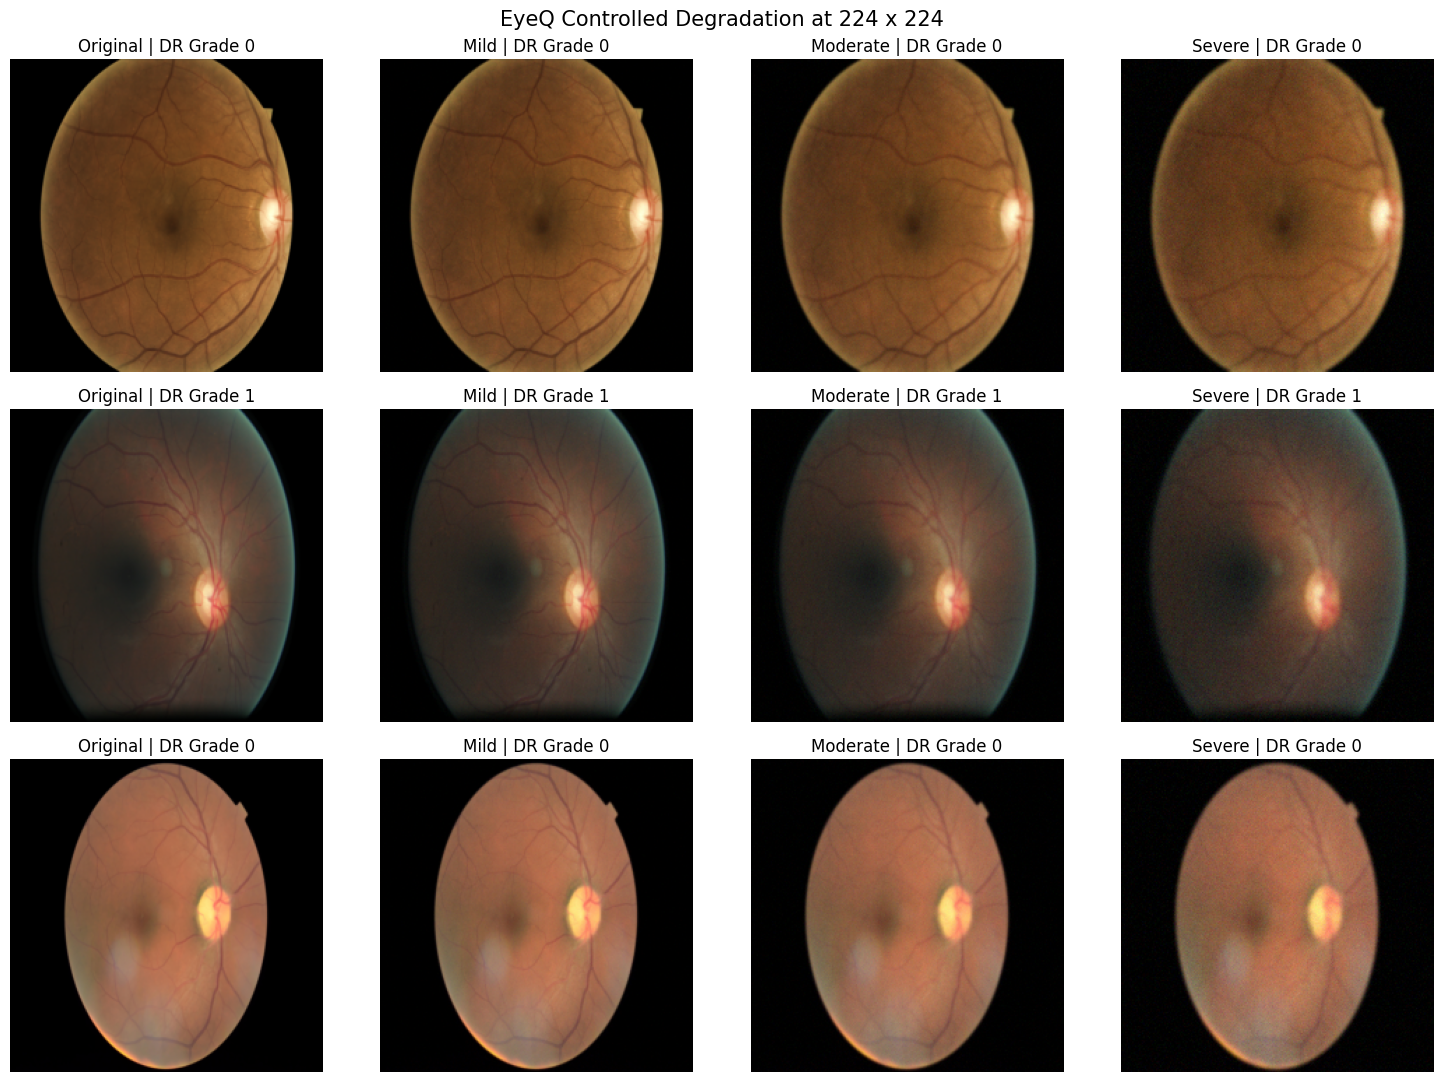

Visualization completed.
ImageNet normalization reversed.
All images displayed within RGB range [0, 1].


In [47]:

# ============================================================
# STEP 5E: CORRECTED VISUAL DEGRADATION INSPECTION
# Reverse ImageNet normalization before displaying images.
# ============================================================

import matplotlib.pyplot as plt
import random
import torch

# ImageNet normalization parameters
IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)


def denormalize_image(tensor):

    image = (
        tensor.detach().cpu() * IMAGENET_STD
        + IMAGENET_MEAN
    )

    return image.clamp(0, 1).permute(1, 2, 0).numpy()


# Reproducible sample selection
random.seed(42)

sample_indices = random.sample(
    range(len(controlled_val_datasets["mild"])),
    3
)

levels = ["mild", "moderate", "severe"]

fig, axes = plt.subplots(
    3, 4,
    figsize=(15, 11)
)

for row, idx in enumerate(sample_indices):

    for col, level in enumerate(
        ["original"] + levels
    ):

        dataset_level = (
            "mild" if level == "original" else level
        )

        sample = controlled_val_datasets[dataset_level][idx]

        label = int(sample["label"])

        if level == "original":
            image_tensor = sample["original"]
        else:
            image_tensor = sample["degraded"]

        image_np = denormalize_image(image_tensor)

        axes[row, col].imshow(image_np)

        axes[row, col].set_title(
            f"{level.capitalize()} | DR Grade {label}"
        )

        axes[row, col].axis("off")

plt.suptitle(
    "EyeQ Controlled Degradation at 224 x 224",
    fontsize=15
)

plt.tight_layout()
plt.show()

print("Visualization completed.")
print("ImageNet normalization reversed.")
print("All images displayed within RGB range [0, 1].")


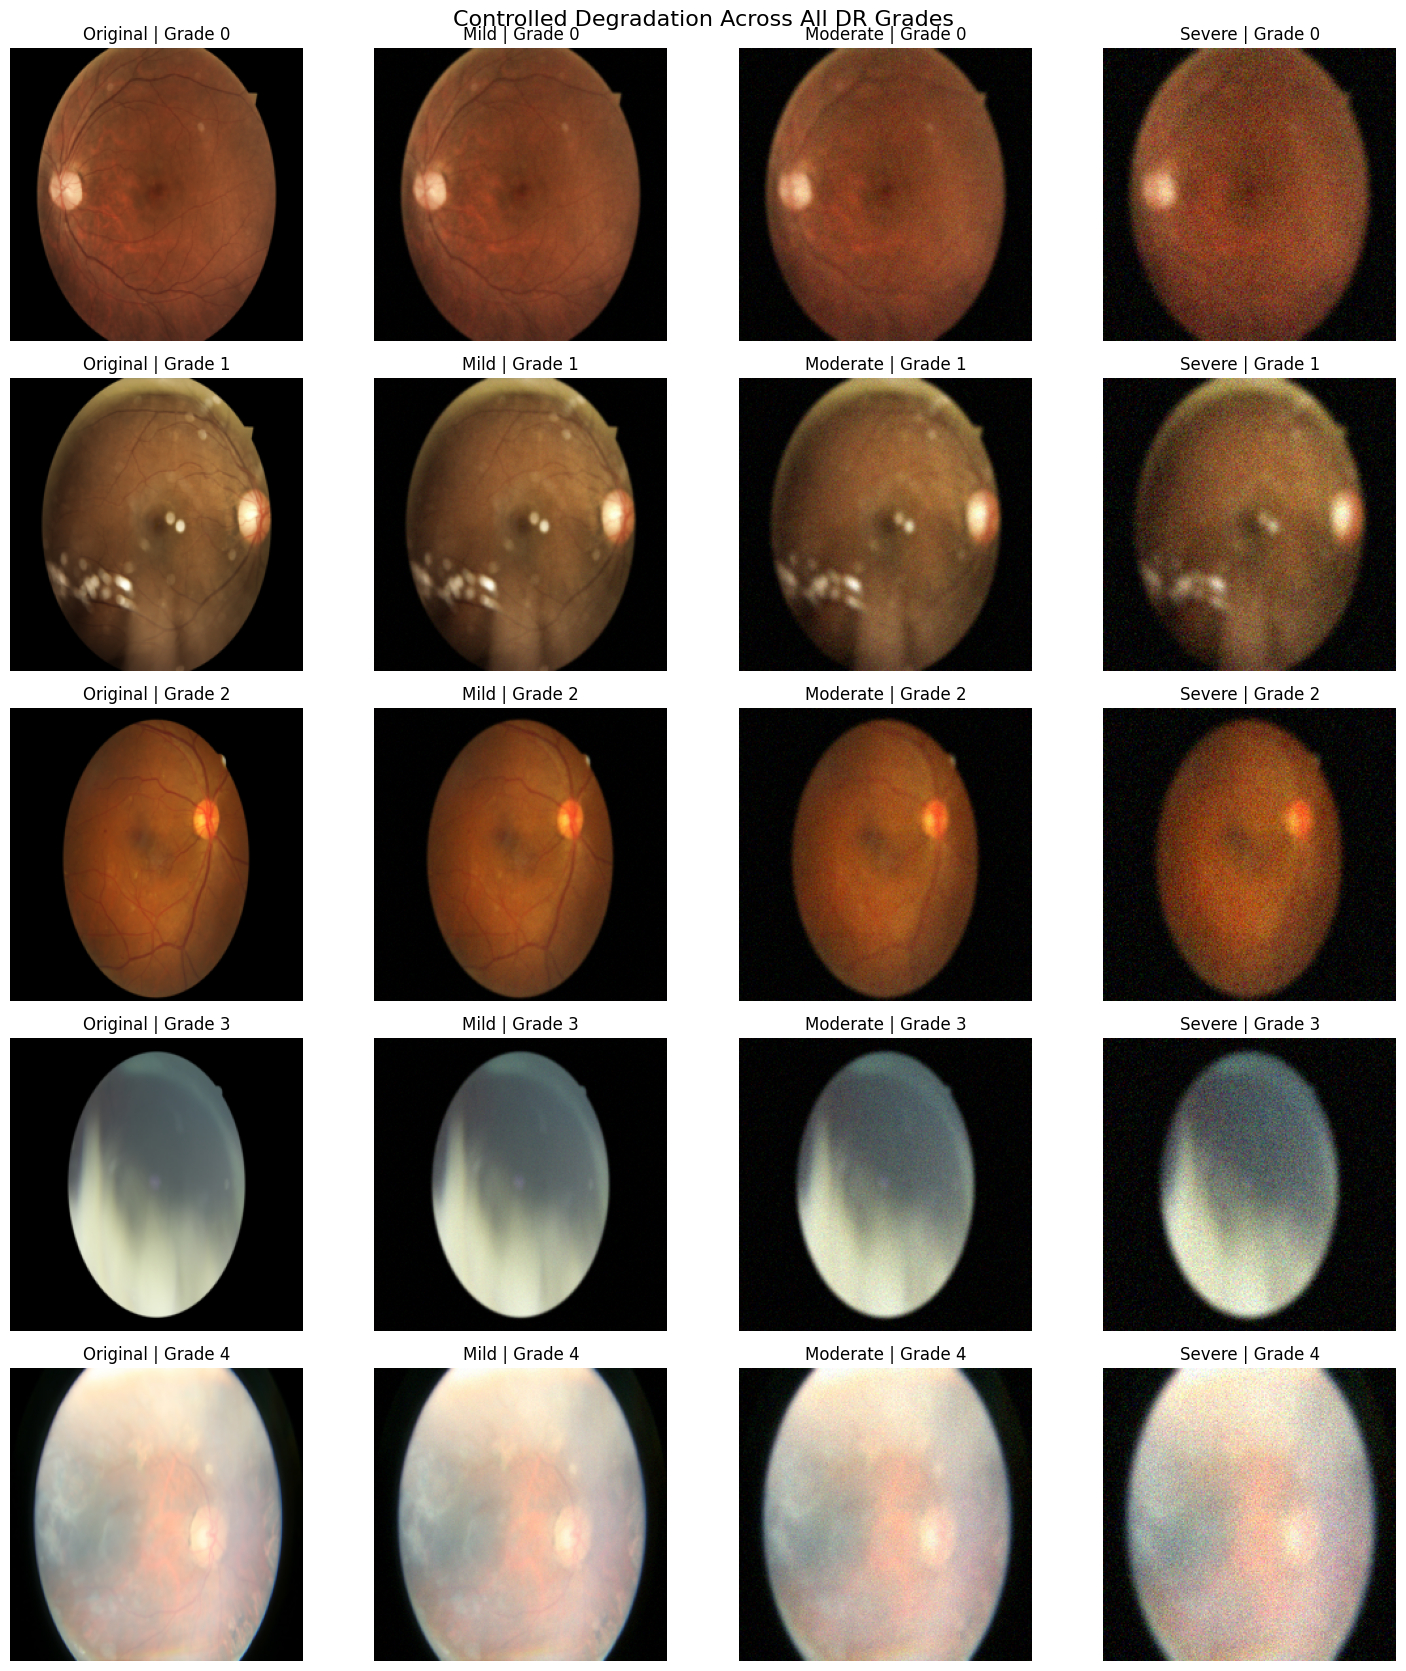

Selected validation samples:
DR Grade 0: validation index 1790
DR Grade 1: validation index 352
DR Grade 2: validation index 96
DR Grade 3: validation index 1339
DR Grade 4: validation index 840


In [39]:

# ============================================================
# STEP 5F: STRATIFIED DR-GRADE DEGRADATION INSPECTION
# One validation image from each DR grade (0-4).
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import random

random.seed(42)

grades = [0, 1, 2, 3, 4]
levels = ["original", "mild", "moderate", "severe"]

# Select one validation sample per DR grade
selected_indices = {}

for grade in grades:

    candidates = np.flatnonzero(
        val_df["DR_grade"].to_numpy() == grade
    )

    assert len(candidates) > 0, (
        f"No validation images found for DR grade {grade}"
    )

    selected_indices[grade] = int(
        random.choice(candidates.tolist())
    )

fig, axes = plt.subplots(
    5, 4,
    figsize=(15, 17)
)

for row, grade in enumerate(grades):

    idx = selected_indices[grade]

    for col, level in enumerate(levels):

        dataset_level = (
            "mild" if level == "original" else level
        )

        sample = controlled_val_datasets[dataset_level][idx]

        image_tensor = (
            sample["original"]
            if level == "original"
            else sample["degraded"]
        )

        image_np = denormalize_image(image_tensor)

        axes[row, col].imshow(image_np)

        axes[row, col].set_title(
            f"{level.capitalize()} | Grade {grade}"
        )

        axes[row, col].axis("off")

plt.suptitle(
    "Controlled Degradation Across All DR Grades",
    fontsize=16
)

plt.tight_layout()
plt.show()

print("Selected validation samples:")

for grade, idx in selected_indices.items():
    print(f"DR Grade {grade}: validation index {idx}")


In [40]:

# ============================================================
# STEP 5G: SELECTED IMAGE QUALITY METADATA
# Connect DR grade samples with original EyeQ quality labels.
# ============================================================

QUALITY_NAMES = {
    0: "Good",
    1: "Usable",
    2: "Reject"
}

print("=" * 65)
print("SELECTED VALIDATION IMAGE METADATA")
print("=" * 65)

for grade, idx in selected_indices.items():

    row = controlled_val_datasets["mild"].dataframe.iloc[idx]

    quality = int(row["quality"])

    print(f"\nDR Grade: {grade}")
    print(f"Validation index: {idx}")
    print(f"EyeQ quality: {QUALITY_NAMES[quality]}")
    print(f"Quality label: {quality}")
    print(f"Image filename: {row['image']}")

print("\nMetadata inspection completed.")


SELECTED VALIDATION IMAGE METADATA

DR Grade: 0
Validation index: 1790
EyeQ quality: Good
Quality label: 0
Image filename: 38744_left.jpeg

DR Grade: 1
Validation index: 352
EyeQ quality: Usable
Quality label: 1
Image filename: 15554_right.jpeg

DR Grade: 2
Validation index: 96
EyeQ quality: Good
Quality label: 0
Image filename: 11703_right.jpeg

DR Grade: 3
Validation index: 1339
EyeQ quality: Reject
Quality label: 2
Image filename: 31647_left.jpeg

DR Grade: 4
Validation index: 840
EyeQ quality: Reject
Quality label: 2
Image filename: 23433_left.jpeg

Metadata inspection completed.


In [41]:

# ============================================================
# STEP 5H: DR GRADE vs EYEQ IMAGE QUALITY DISTRIBUTION
# Analyze the relationship across the complete validation set.
# ============================================================

import pandas as pd

DR_NAMES = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative"
}

QUALITY_NAMES = {
    0: "Good",
    1: "Usable",
    2: "Reject"
}

analysis_df = val_df.copy()

analysis_df["DR_name"] = (
    analysis_df["DR_grade"].map(DR_NAMES)
)

analysis_df["quality_name"] = (
    analysis_df["quality"].map(QUALITY_NAMES)
)

print("=" * 70)
print("DR GRADE vs EYEQ QUALITY DISTRIBUTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. CROSS-TABULATION: IMAGE COUNTS
# ------------------------------------------------------------

grade_quality_counts = pd.crosstab(
    analysis_df["DR_name"],
    analysis_df["quality_name"]
).reindex(
    index=list(DR_NAMES.values()),
    columns=list(QUALITY_NAMES.values()),
    fill_value=0
)

print("\nIMAGE COUNTS")
display(grade_quality_counts)

# ------------------------------------------------------------
# 2. ROW-WISE PERCENTAGES
# Each DR grade sums to approximately 100%.
# ------------------------------------------------------------

grade_quality_percentages = (
    pd.crosstab(
        analysis_df["DR_name"],
        analysis_df["quality_name"],
        normalize="index"
    ) * 100
).reindex(
    index=list(DR_NAMES.values()),
    columns=list(QUALITY_NAMES.values()),
    fill_value=0
)

print("\nQUALITY DISTRIBUTION WITHIN EACH DR GRADE (%)")
display(grade_quality_percentages.round(2))

# ------------------------------------------------------------
# 3. COLUMN-WISE PERCENTAGES
# Each quality category sums to approximately 100%.
# ------------------------------------------------------------

quality_grade_percentages = (
    pd.crosstab(
        analysis_df["quality_name"],
        analysis_df["DR_name"],
        normalize="index"
    ) * 100
).reindex(
    index=list(QUALITY_NAMES.values()),
    columns=list(DR_NAMES.values()),
    fill_value=0
)

print("\nDR GRADE DISTRIBUTION WITHIN EACH QUALITY CATEGORY (%)")
display(quality_grade_percentages.round(2))

# ------------------------------------------------------------
# 4. VERIFY TOTAL COUNTS
# ------------------------------------------------------------

print("\nTOTAL VALIDATION IMAGES:", len(analysis_df))

print("\nQUALITY TOTALS")
print(analysis_df["quality_name"].value_counts())

print("\nDR GRADE TOTALS")
print(analysis_df["DR_name"].value_counts())

print("\nDistribution analysis completed.")


DR GRADE vs EYEQ QUALITY DISTRIBUTION

IMAGE COUNTS


quality_name,Good,Usable,Reject
DR_name,,,
No DR,1281,270,296
Mild,143,26,29
Moderate,238,61,71
Severe,30,18,24
Proliferative,5,10,31



QUALITY DISTRIBUTION WITHIN EACH DR GRADE (%)


quality_name,Good,Usable,Reject
DR_name,,,
No DR,69.36,14.62,16.03
Mild,72.22,13.13,14.65
Moderate,64.32,16.49,19.19
Severe,41.67,25.00,33.33
Proliferative,10.87,21.74,67.39



DR GRADE DISTRIBUTION WITHIN EACH QUALITY CATEGORY (%)


DR_name,No DR,Mild,Moderate,Severe,Proliferative
quality_name,,,,,
Good,75.49,8.43,14.02,1.77,0.29
Usable,70.13,6.75,15.84,4.68,2.60
Reject,65.63,6.43,15.74,5.32,6.87



TOTAL VALIDATION IMAGES: 2533

QUALITY TOTALS
quality_name
Good      1697
Reject     451
Usable     385
Name: count, dtype: int64

DR GRADE TOTALS
DR_name
No DR            1847
Moderate          370
Mild              198
Severe             72
Proliferative      46
Name: count, dtype: int64

Distribution analysis completed.


In [42]:

# ============================================================
# STEP 5I: BASELINE PERFORMANCE BY ORIGINAL EYEQ QUALITY
# Evaluate both baseline models across quality categories
# and all four image conditions.
# ============================================================

import numpy as np
import torch
import gc
from torch.utils.data import Subset

QUALITY_NAMES = {
    0: "Good",
    1: "Usable",
    2: "Reject"
}

CONDITIONS = [
    "original",
    "mild",
    "moderate",
    "severe"
]

QUALITY_RESULTS = {}

print("=" * 75)
print("BASELINE PERFORMANCE BY ORIGINAL EYEQ QUALITY")
print("=" * 75)

# ------------------------------------------------------------
# 1. IDENTIFY VALIDATION INDICES BY QUALITY
# ------------------------------------------------------------

quality_indices = {
    quality: np.flatnonzero(
        val_df["quality"].to_numpy() == quality
    ).tolist()
    for quality in QUALITY_NAMES
}

print("\nVALIDATION SAMPLE COUNTS")

for quality, name in QUALITY_NAMES.items():
    print(f"{name}: {len(quality_indices[quality])}")

# ------------------------------------------------------------
# 2. EVALUATE BOTH BASELINE ARCHITECTURES
# ------------------------------------------------------------

for model_name in ["ResNet50", "ConvNeXt Tiny"]:

    print("\n" + "=" * 75)
    print("ARCHITECTURE:", model_name)
    print("=" * 75)

    model = create_experiment_model(model_name)
    model.eval()

    for quality, quality_name in QUALITY_NAMES.items():

        indices = quality_indices[quality]

        print(f"\nOriginal EyeQ quality: {quality_name}")
        print("Sample count:", len(indices))

        for condition in CONDITIONS:

            dataset_level = (
                "mild" if condition == "original"
                else condition
            )

            subset = Subset(
                controlled_val_datasets[dataset_level],
                indices
            )

            image_key = (
                "original" if condition == "original"
                else "degraded"
            )

            metrics = evaluate_dr_condition(
                model,
                subset,
                image_key=image_key
            )

            QUALITY_RESULTS[
                (model_name, quality_name, condition)
            ] = {
                "accuracy": metrics["accuracy"],
                "macro_f1": metrics["macro_f1"],
                "sample_count": len(indices)
            }

            print(
                f"{condition:10s} | "
                f"Accuracy: {metrics['accuracy']:.4f} | "
                f"Macro F1: {metrics['macro_f1']:.4f}"
            )

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 3. SUMMARY TABLE
# ------------------------------------------------------------

import pandas as pd

summary_rows = []

for key, metrics in QUALITY_RESULTS.items():

    model_name, quality_name, condition = key

    summary_rows.append({
        "Architecture": model_name,
        "EyeQ Quality": quality_name,
        "Condition": condition,
        "Samples": metrics["sample_count"],
        "Accuracy": metrics["accuracy"],
        "Macro F1": metrics["macro_f1"]
    })
quality_results_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 75)
print("QUALITY-STRATIFIED BASELINE SUMMARY")
print("=" * 75)

display(
    quality_results_df.round(4)
)

print("\nQuality-stratified evaluation completed.")
print("No model training was performed.")


BASELINE PERFORMANCE BY ORIGINAL EYEQ QUALITY

VALIDATION SAMPLE COUNTS
Good: 1697
Usable: 385
Reject: 451

ARCHITECTURE: ResNet50

Original EyeQ quality: Good
Sample count: 1697
original   | Accuracy: 0.7065 | Macro F1: 0.4822
mild       | Accuracy: 0.3654 | Macro F1: 0.2356
moderate   | Accuracy: 0.0159 | Macro F1: 0.0140
severe     | Accuracy: 0.0047 | Macro F1: 0.0034

Original EyeQ quality: Usable
Sample count: 385
original   | Accuracy: 0.6545 | Macro F1: 0.4494
mild       | Accuracy: 0.3039 | Macro F1: 0.2100
moderate   | Accuracy: 0.0286 | Macro F1: 0.0118
severe     | Accuracy: 0.0260 | Macro F1: 0.0102

Original EyeQ quality: Reject
Sample count: 451
original   | Accuracy: 0.5721 | Macro F1: 0.3725
mild       | Accuracy: 0.3149 | Macro F1: 0.2399
moderate   | Accuracy: 0.1175 | Macro F1: 0.0906
severe     | Accuracy: 0.0931 | Macro F1: 0.0577

ARCHITECTURE: ConvNeXt Tiny

Original EyeQ quality: Good
Sample count: 1697
original   | Accuracy: 0.7071 | Macro F1: 0.4655
mild     

,Architecture,EyeQ Quality,Condition,Samples,Accuracy,Macro F1
0,ResNet50,Good,original,1697,0.7065,0.4822
1,ResNet50,Good,mild,1697,0.3654,0.2356
2,ResNet50,Good,moderate,1697,0.0159,0.0140
3,ResNet50,Good,severe,1697,0.0047,0.0034
4,ResNet50,Usable,original,385,0.6545,0.4494
5,ResNet50,Usable,mild,385,0.3039,0.2100
6,ResNet50,Usable,moderate,385,0.0286,0.0118
7,ResNet50,Usable,severe,385,0.0260,0.0102
8,ResNet50,Reject,original,451,0.5721,0.3725
9,ResNet50,Reject,mild,451,0.3149,0.2399



Quality-stratified evaluation completed.
No model training was performed.
